In [1]:
import numpy as np
import csv
import time
import os
import itertools
import pandas as pd
import matplotlib.pyplot as plt
import skimage
import glob
from matplotlib.lines import Line2D
import tqdm
import pickle
from scipy.spatial import cKDTree
from statsmodels.stats.proportion import proportions_ztest
from skimage.morphology import binary_dilation, disk
from morphcia.fast_morph_scripts import vectorized_split_cells_morph

In [3]:
sample_organs = pd.read_csv('sample_organs.txt', sep='\t')

In [4]:
BASE_DIR = '/home/aplante/aplante_diskmnt/mCRC/xenium_5k/Evan/morphcia/'
gene_start_index = 13
dist_thresh = 30 
# np.unique(seurat_table["broad_cell_type"])

In [5]:
filenames = glob.glob('morphcia/seurat_to_python/*.csv')
lung_ids = []
colon_ids = []
liver_ids = []
breast_ids = []
section_ids = []
for filename in filenames:
    section_id = filename.split('/')[-1].split('.csv')[0]
    organ = sample_organs[sample_organs['Section ID'] == section_id]['Site']
    if len(organ) != 1:
        raise Exception(f"Unexpected number of matches for {section_id}: {len(organ)}")
    organ = organ.values[0]
    
    if organ == 'Colon':
        colon_ids.append(section_id)
    elif organ == 'Lung':
        lung_ids.append(section_id)
    elif organ == 'Liver':
        liver_ids.append(section_id)
    elif organ == 'Breast':
        breast_ids.append(section_id)
    else:
        print(f"Unknown organ '{organ}' for section_id {section_id}")

    section_ids.append(section_id)
# Optionally, print the collected IDs
print("Colon IDs:", colon_ids)
print("Lung IDs:", lung_ids)
print("Liver IDs:", liver_ids)
print("Breast IDs:", breast_ids)

cross_organ_matches = [
    ["S16-44514-E7U2", "S16-44514-B3U1"],
    ["S15-1909-A5U1", "S15-1909-D2U1"],
    ["S15-32775-D4U2", "S15-32775-A1U2"],
    ["S16-38794-A4U2", "S16-38794-E2U1"],
    ["S13-31378-E7U1", "S13-31378-B1U1"],
    ["HT472C1-S1H3FP1U1", "HT472C1-M1FP1U1"]
]


Colon IDs: ['S16-44514-E7U2', 'S15-1909-A5U1', 'S15-32775-D4U2', 'S16-38794-A4U2', 'S13-31378-E7U1', 'HT472C1-S1H3FP1U1', 'S13-18424-B5U1']
Lung IDs: ['S15-23849-A2U1', 'S15-21169-A1U1', 'S17-16442-AFR1U1', 'CM478C2-A3-Tp1Fp1U1', 'CM478C1-D4-Tp1Fp1U1', 'CM354C1-A2-Tp1Fp1U1']
Liver IDs: ['S16-44514-B3U1', 'S15-1909-D2U1', 'S16-38794-E2U1', 'S15-32775-A1U2', 'HT413C1-Th1K2A1U2', 'S13-31378-B1U1', 'HT472C1-M1FP1U1']
Breast IDs: ['S20-46186-A16U1']


In [6]:
cell_types = [
    "Hepatocyte",
    "APCDD1 tumor",
    "Cholangiocyte",
    "Stem-like tumor",
    "CD4_Treg",
    "Unknown",
    "mCAF",
    "RTM",
    "Necrosis",
    "TAM",
    "CD4_Resting_T",
    "APC-like",
    "B cell",
    "CD8_TRM_T",
    "Plasma cell",
    "fibroblast_WNT5A",
    "CD8_Effector_T",
    "stromal fibroblast",
    "Endothelial cell",
    "TAM_hypoxic-angiogenic",
    "CD8_EM_T",
    "CD4_Th17_T",
    "Hypoxic",
    "iCAF",
    "stellate cell",
    "smooth muscle",
    "Hypoxic-EMT",
    "pericyte",
    "Hypoxic-Repair",
    "Proliferative stem-like tumor",
    "Proliferative tumor",
    "vCAF",
    "CD4_naive/CM_T",
    "mCAF_WNT5A",
    "Intestinal epithelium",
    "Aveolar epithelium",
    "Bronchial gland",
    "Breast ductal epithelium"
]


In [7]:
[x for x in cell_types if "TAM" in x]

['TAM', 'TAM_hypoxic-angiogenic']

In [8]:
tumor_cell_types = [
    "APCDD1 tumor",
    "Stem-like tumor",
    "Proliferative stem-like tumor",
    "Proliferative tumor"
]

one_way_pairs = [
    ['mCAF', 'TAM'],
    ['fibroblast_WNT5A', 'TAM'],
    ['CD8_TRM_T', 'TAM']
]
# Create a copy of one_way_pairs so that we're not iterating over a list we're modifying
cell_type_pairs = one_way_pairs.copy()

for pair in one_way_pairs:
    cell_type_pairs.append([pair[1], pair[0]])

In [9]:
donor_cell_types = ['fibroblast_WNT5A', 'mCAF', 'CD8_TRM_T', 'TAM']

In [10]:
cell_type_pairs

[['mCAF', 'TAM'],
 ['fibroblast_WNT5A', 'TAM'],
 ['CD8_TRM_T', 'TAM'],
 ['TAM', 'mCAF'],
 ['TAM', 'fibroblast_WNT5A'],
 ['TAM', 'CD8_TRM_T']]

In [17]:
checkpoint = True # write checkpoint file
check_continue = True #continue from checkpoint file

section_hit_dict = {}

if check_continue:
    with open("checkpoint.pkl", "rb") as f:
        section_hit_dict = pickle.load(f)

for section_id in tqdm.tqdm(section_ids):
    print(section_id)
    if section_id in section_hit_dict.keys():
        print(section_id, 'exists. Skipping...')
        continue
    
    seurat_table = pd.read_csv(BASE_DIR + 'seurat_to_python/' + section_id + '.csv', low_memory=False)
    hit_dict = {}

    for donor_cell_type in tqdm.tqdm(donor_cell_types):
        cell_types_key = donor_cell_type+'_2_tumor'
        receiver_cells = seurat_table[seurat_table["all_cell_type"].isin(tumor_cell_types)]

    # for donor_cell_type, receiver_cell_type in cell_type_pairs:
    #     cell_types_key = donor_cell_type+'_2_'+receiver_cell_type
    #     receiver_cells = seurat_table[seurat_table["all_cell_type"]==receiver_cell_type]

        donor_cells = seurat_table[seurat_table["all_cell_type"]==donor_cell_type]

        if receiver_cells.shape[0] == 0 or donor_cells.shape[0] == 0:
            tot_in = 0
            tot_out = 0
        else:
            cells_in, cells_out = vectorized_split_cells_morph(receiver_cells, donor_cells, grid_size=5, distance_threshold=30)
            tot_in = len(cells_in)
            tot_out = len(cells_out)

        hits = []
        for i, gene_array in enumerate(receiver_cells.iloc[:, gene_start_index:].values.T):

            if tot_in==0 or tot_out==0:
                if i==0:
                    print(section_id, 'has 0 cells in proximity, skipping...')
                hits.append([receiver_cells.columns[gene_start_index + i], 0, 0, 0, 0, 0, 0, 0])
                continue

            num_inwards = int(sum(gene_array[cells_in]>0))
            num_outwards = int(sum(gene_array[cells_out]>0))
            prop_inwards = num_inwards/tot_in*100
            prop_outwards = num_outwards/tot_out*100

            counts = np.array([num_inwards, num_outwards])
            nobs = np.array([tot_in, tot_out])
            z_stat, p_val = proportions_ztest(counts, nobs)

            hits.append([receiver_cells.columns[gene_start_index + i], prop_inwards, prop_outwards, num_inwards, num_outwards, tot_in, tot_out, p_val])

        hit_dict[cell_types_key] = hits
    section_hit_dict[section_id] = hit_dict
    if checkpoint:
        with open("checkpoint.pkl", "wb") as f:

            pickle.dump(section_hit_dict, f)

  0%|                                                                                                                                | 0/21 [00:00<?, ?it/s]

S16-44514-E7U2
S16-44514-E7U2 exists. Skipping...
S16-44514-B3U1



%|                                                                                                                                 | 0/4 [00:00<?, ?it/s]
%|██████████████████████████████                                                                                          | 1/4 [05:22<16:07, 322.57s/it]
%|████████████████████████████████████████████████████████████                                                            | 2/4 [10:50<10:51, 325.88s/it]
%|██████████████████████████████████████████████████████████████████████████████████████████                              | 3/4 [16:00<05:18, 318.34s/it]
 10%|███████████                                                                                                         | 2/21 [36:19<5:45:09, 1089.96s/it]

S15-23849-A2U1



%|                                                                                                                                 | 0/4 [00:00<?, ?it/s]
%|██████████████████████████████                                                                                          | 1/4 [01:52<05:38, 112.80s/it]
%|████████████████████████████████████████████████████████████                                                            | 2/4 [03:47<03:47, 113.72s/it]
%|██████████████████████████████████████████████████████████████████████████████████████████                              | 3/4 [05:39<01:53, 113.12s/it]
 14%|████████████████▋                                                                                                    | 3/21 [48:45<4:43:59, 946.66s/it]

S15-21169-A1U1


... (37 outputs left out)

CM354C1-A2-Tp1Fp1U1



100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 4/4 [00:00<00:00, 96.49it/s]


CM354C1-A2-Tp1Fp1U1 has 0 cells in proximity, skipping...
CM354C1-A2-Tp1Fp1U1 has 0 cells in proximity, skipping...
CM354C1-A2-Tp1Fp1U1 has 0 cells in proximity, skipping...
CM354C1-A2-Tp1Fp1U1 has 0 cells in proximity, skipping...


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 21/21 [4:18:09<00:00, 737.60s/it]


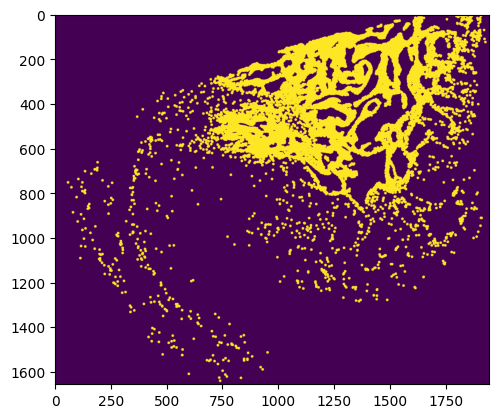

In [17]:
plt.imshow(donor_cell_dilated_mask)

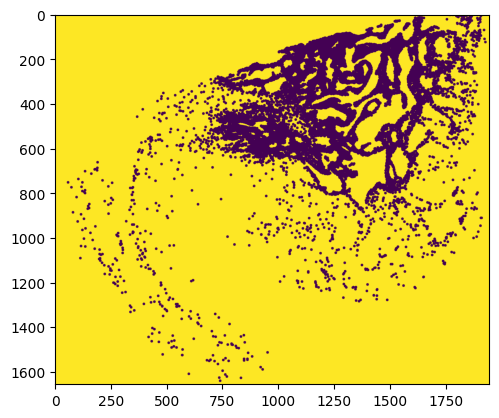

In [40]:
plt.imshow(inverted_donor_cell_dilated_mask)

In [19]:
import pickle

with open("morph5_tumor_section_hit_dict.pkl", "wb") as f:
    pickle.dump(section_hit_dict, f)

# with open("TAM_section_hit_dict.pkl", "rb") as f:
#     section_hit_dict = pickle.load(f)

In [18]:
for key in section_hit_dict['S16-44514-E7U2'].keys():
    print(key)

fibroblast_WNT5A_2_tumor
mCAF_2_tumor
CD8_TRM_T_2_tumor
TAM_2_tumor


In [12]:
# for key in section_hit_dict['S16-44514-E7U2'].keys():
#     for section_id in section_hit_dict.keys():
#         print(section_id, key, section_hit_dict[section_id][key][0][5], section_hit_dict[section_id][key][0][6])

In [20]:
pairs = [
    ["S16-44514-E7U2", "S16-44514-B3U1"],
    ["S15-1909-A5U1", "S15-1909-D2U1"],
    ["S15-32775-D4U2", "S15-32775-A1U2"],
    ["S16-38794-A4U2", "S16-38794-E2U1"],
    ["S13-31378-E7U1", "S13-31378-B1U1"],
    ["HT472C1-S1H3FP1U1", "HT472C1-M1FP1U1"]
]

cell_type_key = 'fibroblast_WNT5A_2_tumor'
sig_thresh = 0.05
min_percent = 10
min_average_fold_change=1.3
all_genes = [x[0] for x in section_hit_dict['S16-44514-E7U2'][cell_type_key]]

donor_cell_type, receiver_cell_type = cell_type_key.split('_2_')

gene_diff_directions = []
for gene in all_genes:
    col_diff_directions = ''
    liver_diff_directions = ''
    col_fold_change = 0
    liver_fold_change = 0
    for pair in pairs:
        colon_sec_id = pair[0]
        col_in = [x[1] for x in section_hit_dict[colon_sec_id][cell_type_key] if x[0]==gene][0]
        col_out = [x[2] for x in section_hit_dict[colon_sec_id][cell_type_key] if x[0]==gene][0]
        colon_diff = col_in-col_out
        col_p_val = float([x[7] for x in section_hit_dict[colon_sec_id][cell_type_key] if x[0]==gene][0])

        
        if col_p_val>sig_thresh or (col_in<min_percent and col_out<min_percent):
            col_diff_direction='O'
        elif colon_diff>=0:
            col_diff_direction='+'
            if col_out!=0:
                col_fold_change+=(col_in/col_out)/len(pairs)
            else:
                col_fold_change = 100 # It will be filtered by min_percent, unless it is a big difference, in which case we want it
        else:
            col_diff_direction='-'
            if col_in!=0:
                col_fold_change+=(col_out/col_in)/len(pairs)
            else:
                col_fold_change = 100
        
        liver_sec_id = pair[1]
        liver_in = [x[1] for x in section_hit_dict[liver_sec_id][cell_type_key] if x[0]==gene][0]
        liver_out = [x[2] for x in section_hit_dict[liver_sec_id][cell_type_key] if x[0]==gene][0]
        liver_diff = liver_in-liver_out
        liver_p_val = float([x[7] for x in section_hit_dict[liver_sec_id][cell_type_key] if x[0]==gene][0])
        
        if liver_p_val>sig_thresh or (liver_in<min_percent and liver_out<min_percent):
            liver_diff_direction='O'
        elif liver_diff>=0:
            liver_diff_direction='+'
            if liver_out!=0:
                liver_fold_change+=(liver_in/liver_out)/len(pairs)
            else:
                liver_fold_change = 100
        else:
            liver_diff_direction='-'
            if liver_in!=0:
                liver_fold_change+=(liver_out/liver_in)/len(pairs)
            else:
                liver_fold_change = 100

        col_diff_directions+=col_diff_direction
        liver_diff_directions+=liver_diff_direction
        
    if col_fold_change<min_average_fold_change and liver_fold_change<min_average_fold_change:
        gene_diff_directions.append([gene, 'O'*len(pairs), 'O'*len(pairs)])
    elif col_fold_change<min_average_fold_change:
        gene_diff_directions.append([gene, 'O'*len(pairs), liver_diff_directions])
    elif liver_fold_change<min_average_fold_change:
        gene_diff_directions.append([gene, col_diff_directions, 'O'*len(pairs)])
    else:
        gene_diff_directions.append([gene, col_diff_directions, liver_diff_directions])

In [41]:
UPcol_UPliver = [x for x in gene_diff_directions if x[1].count('+')>=5 and x[2].count('+')>=4]
for x in UPcol_UPliver:
    print(x)

In [42]:
DOWNcol_DOWNliver = [x for x in gene_diff_directions if x[1].count('-')>=5 and x[2].count('-')>=4]
for x in DOWNcol_DOWNliver:
    print(x)

In [43]:
DOWNcol_NULLliver = [x for x in gene_diff_directions if x[1].count('-')>=5 and x[2].count('-')<=2]
for x in DOWNcol_NULLliver:
    print(x)

['ALDOA', '-----+', 'OOOOOO']
['CA12', '-----+', 'OOOOOO']
['P4HA1', '-----+', 'OOOOOO']
['TFF3', '-----+', 'OOOOOO']


In [44]:
NULLcol_DOWNliver = [x for x in gene_diff_directions if x[2].count('-')>=5 and x[1].count('-')<=2]
for x in NULLcol_DOWNliver:
    print(x)

In [45]:
UPcol_NULLliver = [x for x in gene_diff_directions if x[1].count('+')>=5 and x[2].count('+')<=2]
for x in UPcol_NULLliver:
    print(x)

['CFB', '++++++', 'OOOOOO']
['MAP4K4', '++++++', 'OOOOOO']
['PROX1', '-+++++', 'OOOOOO']


In [46]:
NULLcol_UPliver = [x for x in gene_diff_directions if x[2].count('+')>=5 and x[1].count('+')<=2]
for x in NULLcol_UPliver:
    print(x)

In [47]:
hit_genes = []
hit_genes += [x[0] for x in UPcol_UPliver]
hit_genes += [x[0] for x in DOWNcol_DOWNliver]
hit_genes += [x[0] for x in DOWNcol_NULLliver]
hit_genes += [x[0] for x in NULLcol_DOWNliver]
hit_genes += [x[0] for x in UPcol_NULLliver]
hit_genes += [x[0] for x in NULLcol_UPliver]
hit_genes = np.unique(hit_genes)

for x in hit_genes:
    print(x)

ALDOA
CA12
CFB
MAP4K4
P4HA1
PROX1
TFF3


In [48]:
annotated_genes = [
    "COL7A1", "EDNRA", "LOXL2", "MMP11", "NES", "NOTCH3", "CCDC80", "CXCL12", "IL6ST", "PDGFRA",
    "NOTCH1", "PLAU", "FAP", "COL11A1", "CTHRC1", "ADAM12", "ANGPTL2", "CCN1", "COMP", "ITGA1",
    "ITGA5", "LOX", "GREM1", "INHBA", "POSTN", "PALLD", "OLFML3", "TGFB1I1", "SULF1", "MYH11",
    "SDC2", "WNT5A", "PDGFA", "PDGFC", "NECTIN2", "PLAUR", "SPHK1", "SPP1", "TGFBR1", "PKM",
    "PGK1", "ASPN", "BMP8A", "ITGA4", "ADAMTS12", "APCDD1", "CCN4", "DKK3", "LTBP1", "MME",
    "SOD1", "SPON2", "TP53", "PLAT", "PYGB", "VASP", "C3", "FLRT2", "CFH", "ITGA9",
    "LAMA2", "CACNA1H", "CTSC", "ECE1", "FURIN", "GSTO1", "MYO1B", "PTPRG", "C7", "ITGAV",
    "CD276", "ANO1", "CREB3L1", "CSRP1", "SFRP4", "MCAM", "RAI14", "S1PR3", "ZYX", "MAP3K7CL",
    "AHCY", "HINT1", "ITIH5", "LRRC59", "MAP4K4", "NME1", "NORAD", "PCDH18", "PSMD3", "RBP1",
    "SLC25A1", "SNRPB", "SSRP1", "PPP1CA", "HSPD1", "TKT", "ENTPD1", "F2R", "FILIP1L", "COL18A1",
    "FAT1", "ERRFI1", "ACTN1", "ALDOA", "ATP1A1", "KIF5B", "LASP1", "CORO1C", "IGF2BP2", "PCNA",
    "VDAC1", "YWHAZ", "AFAP1L2", "CCT6A", "MCM7", "MMP11", "ADAMTS1", "ADAMTS2", "BMP2", "BMP5", 
    "HSD17B2", "INSC", "LOXL1", "NREP", "NRG1", "PDGFRB", "THBS2", "TRPA1", "VEGFA",
    "MICAL2", "MYOF", "PTGIS", "PTK2", "SEPTIN5", "SNAI2", "TGFBI"
]


important_genes = [
    "COL7A1", "EDNRA", "LOXL2", "MMP11", "NES", "NOTCH3", "CCDC80", "CXCL12", "IL6ST", "PDGFRA",
    "NOTCH1", "PLAU", "FAP", "COL11A1", "CTHRC1", "ADAM12", "ANGPTL2", "CCN1", "COMP", "ITGA1",
    "ITGA5", "LOX", "GREM1", "INHBA", "POSTN", "PALLD", "OLFML3", "TGFB1I1", "SULF1", "MYH11",
    "SDC2", "WNT5A", "PDGFA", "PDGFC", "NECTIN2", "PLAUR", "SPHK1", "SPP1", "TGFBR1", "PKM",
    "PGK1", "ASPN", "BMP8A", "ITGA4", "ADAMTS12", "APCDD1", "CCN4", "DKK3", "LTBP1", "MME",
    "SOD1", "SPON2", "TP53", "MMP11", "ADAMTS1", "ADAMTS2", "BMP2", "BMP5", "LOXL1", "NRG1", 
    "PDGFRB", "THBS2", "VEGFA", "C7", "MICAL2", "PTGIS", "SNAI2"
]


for y in [str(x) for x in hit_genes if x not in annotated_genes]:
    print(y)

CA12
CFB
P4HA1
PROX1
TFF3


In [49]:
# hit_genes = [str(x) for x in hit_genes if x in important_genes]

In [50]:
min_percent = 5

fold_change_data = []

for gene in hit_genes:
    # Collect data for the current gene
    data = []
    for section_id in section_hit_dict.keys():
        # Each entry is (gene, val_in, val_out, ..., p_val at index 7, etc.)
        hit = [x for x in section_hit_dict[section_id][cell_type_key] if x[0] == gene][0]
        val_in, val_out, p_val = hit[1], hit[2], hit[7]
        data.append([section_id, val_in, val_out, p_val])
    
    # Make a lookup dictionary: section_id -> (val_in, val_out, p_val)
    data_dict = {row[0]: (row[1], row[2], row[3]) for row in data}
    
    # Initialize counters and sums for fold changes
    col_fold_change = 0.0
    liver_fold_change = 0.0
    lung_fold_change = 0.0
    breast_fold_change = 0.0

    # Track how many valid samples (non-zero denominators) we have per organ
    valid_colon = 0
    valid_liver = 0
    valid_lung = 0
    valid_breast = 0

    # Track ALL in/out values, to see if any surpass min_percent
    colon_in_out_values = []
    liver_in_out_values = []
    lung_in_out_values  = []
    breast_in_out_values= []

    # Calculate fold changes for Colon–Liver pairs
    for i, (colon_label, liver_label) in enumerate(pairs):
        colon_in, colon_out, colon_p_val  = data_dict[colon_label]
        liver_in, liver_out, liver_p_val  = data_dict[liver_label]

        # Collect raw values for checking min_percent
        colon_in_out_values.extend([colon_in, colon_out])
        liver_in_out_values.extend([liver_in, liver_out])

        # Accumulate fold-change calculations for Colon
        if colon_out > 0:
            col_fold_change += (colon_in / colon_out)
            valid_colon += 1

        # Accumulate fold-change calculations for Liver
        if liver_out > 0:
            liver_fold_change += (liver_in / liver_out)
            valid_liver += 1
    
    # Calculate fold changes for unpaired Lung samples
    for lung_label in lung_ids:
        lung_in, lung_out, lung_p_val = data_dict[lung_label]
        lung_in_out_values.extend([lung_in, lung_out])
        if lung_out > 0:
            lung_fold_change += (lung_in / lung_out)
            valid_lung += 1
    
    # Calculate fold changes for unpaired Breast samples
    for breast_label in breast_ids:
        breast_in, breast_out, breast_p_val = data_dict[breast_label]
        breast_in_out_values.extend([breast_in, breast_out])
        if breast_out > 0:
            breast_fold_change += (breast_in / breast_out)
            valid_breast += 1
    
    # Compute the average fold changes 
    # If no samples for a particular organ -> 0 or "NA" is your choice.
    avg_col_fold_change    = col_fold_change / valid_colon    if valid_colon    > 0 else 0
    avg_liver_fold_change  = liver_fold_change / valid_liver  if valid_liver    > 0 else 0
    avg_lung_fold_change   = lung_fold_change / valid_lung    if valid_lung     > 0 else 0
    avg_breast_fold_change = breast_fold_change / valid_breast if valid_breast  > 0 else 0

    # --- Check if all in/out values for each organ are below min_percent --- #
    # If so, set the average fold change to "NA"
    if colon_in_out_values and max(colon_in_out_values) < min_percent:
        avg_col_fold_change = "NA"
    if liver_in_out_values and max(liver_in_out_values) < min_percent:
        avg_liver_fold_change = "NA"
    if lung_in_out_values and max(lung_in_out_values) < min_percent:
        avg_lung_fold_change = "NA"
    if breast_in_out_values and max(breast_in_out_values) < min_percent:
        avg_breast_fold_change = "NA"
    
    # Append the fold change data for this gene:
    fold_change_data.append([
        gene,
        avg_col_fold_change,
        avg_liver_fold_change,
        avg_lung_fold_change,
        avg_breast_fold_change
    ])

# Example printout of the data:
for row in fold_change_data:
    gene, col_fc, liver_fc, lung_fc, breast_fc = row
    print(f"Gene: {gene}")
    print(f"  Colon mean fold change: {col_fc}")
    print(f"  Liver mean fold change: {liver_fc}")
    print(f"  Lung mean fold change: {lung_fc}")
    print(f"  Breast mean fold change: {breast_fc}")
    print()


Gene: ALDOA
  Colon mean fold change: 0.8390533817876125
  Liver mean fold change: 0.8736889317352173
  Lung mean fold change: 0.8790311268928246
  Breast mean fold change: 1.033732249198351

Gene: CA12
  Colon mean fold change: 0.8471568233239798
  Liver mean fold change: 0.7518071362076459
  Lung mean fold change: 0.9398158703882867
  Breast mean fold change: 0.7687850114909509

Gene: CFB
  Colon mean fold change: 1.4781730892042202
  Liver mean fold change: 1.0866764168469711
  Lung mean fold change: 1.1065774808624298
  Breast mean fold change: 1.2715088949611144

Gene: MAP4K4
  Colon mean fold change: 1.3377947056368171
  Liver mean fold change: 1.2381859965860655
  Lung mean fold change: 1.317610747589011
  Breast mean fold change: 1.168326635214631

Gene: P4HA1
  Colon mean fold change: 0.7808343411525658
  Liver mean fold change: 0.8700387451047068
  Lung mean fold change: 0.792656781363878
  Breast mean fold change: 1.446706646495575

Gene: PROX1
  Colon mean fold change: 1.29

In [51]:
len(hit_genes)

7

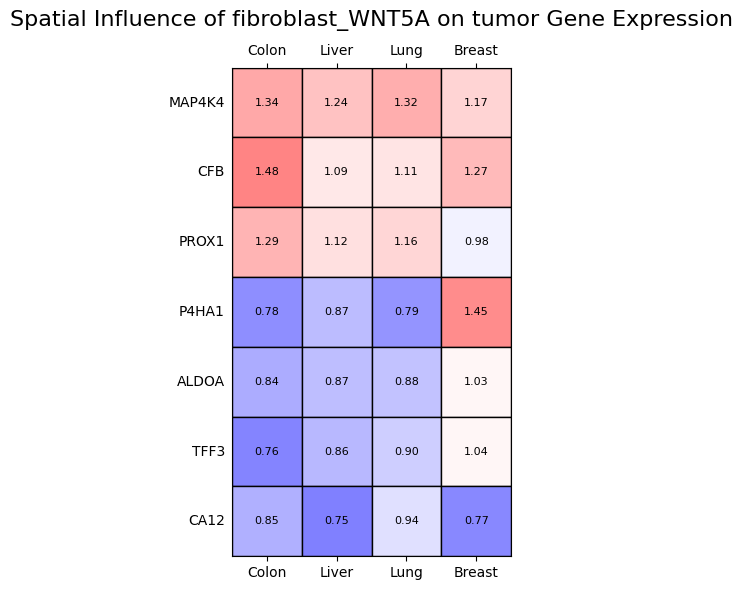

In [52]:
import math
import numpy as np
import matplotlib.pyplot as plt

min_height = 6
min_width = 4

# fold_change_data is a list of lists: [ [gene, col_fc, liver_fc, lung_fc, breast_fc], ... ]
# Some fc values may be "NA" instead of a number.
fold_change_data = sorted(fold_change_data, 
                          key=lambda x: sum([v for v in x[1:] if isinstance(v, (int, float))]) / 
                                        sum([1 for v in x[1:] if isinstance(v, (int, float))]) 
                                        if any(isinstance(v, (int, float)) for v in x[1:]) else 0,
                          reverse=True)

gene_names = [row[0] for row in fold_change_data]
heat_data  = [row[1:] for row in fold_change_data]  # Each row: [Colon, Liver, Lung, Breast]
organ_labels = ["Colon", "Liver", "Lung", "Breast"]
n_organs = len(organ_labels)

max_rows = 7          # Maximum rows per block
n_genes = len(gene_names)
n_blocks = math.ceil(n_genes / max_rows)
gap = 2                 # Increased gap between blocks

# Total columns: each block has n_organs columns plus a gap between blocks (except after the last one)
total_cols = n_blocks * n_organs + (n_blocks - 1) * gap
total_rows = max_rows     # Fixed height per block

height = max(total_rows * 0.5, min_height)
width  = max(total_cols * 0.8, min_width)
fig, ax = plt.subplots(figsize=(width, height))

def normalize_fc(fc):
    """
    Map a fold-change value (fc) to a normalized value for the bwr colormap,
    using a global scale:
      - fc <= 0.3  -> normalized 0.0 (dark blue)
      - fc = 1     -> normalized 0.5 (white)
      - fc >= 4    -> normalized 1.0 (dark red)
    """
    red_max = 2
    blue_min = 0.5
    fc = max(min(fc, red_max), blue_min)
    if fc <= 1:
        return (fc - blue_min) / (1 - blue_min) * 0.5
    else:
        return 0.5 + (fc - 1) / (red_max - 1) * 0.5

# Create heatmap cells.
for i, (gene, row_vals) in enumerate(zip(gene_names, heat_data)):
    block = i // max_rows
    row_in_block = i % max_rows
    y = max_rows - row_in_block - 1  # so first gene appears at top

    for j, fc_value in enumerate(row_vals):
        # x coordinate: shift by block number (including gap) plus the organ column
        x = block * (n_organs + gap) + j

        if isinstance(fc_value, str) and fc_value.upper() == "NA":
            # NA case: color = white (same as normalized 0.5)
            color = plt.cm.bwr(0.5)
            display_text = "NA"
        else:
            # Numeric case
            numeric_val = float(fc_value)
            norm_val = normalize_fc(numeric_val)
            color = plt.cm.bwr(norm_val)
            display_text = f"{numeric_val:.2f}"

        rect = plt.Rectangle((x, y), 1, 1, facecolor=color, edgecolor="black")
        ax.add_patch(rect)
        ax.text(x + 0.5, y + 0.5, display_text, ha="center", va="center", fontsize=8)

# Set x-axis ticks: create ticks for each organ in each block
x_ticks = []
x_tick_labels = []
for block in range(n_blocks):
    for j, organ in enumerate(organ_labels):
        x_tick = block * (n_organs + gap) + j + 0.5
        x_ticks.append(x_tick)
        x_tick_labels.append(organ)

ax.set_xticks(x_ticks)
ax.set_xticklabels(x_tick_labels, fontsize=10)
ax.xaxis.set_ticks_position("both")
ax.tick_params(axis="x", labeltop=True, labelbottom=True)

# Remove default y-ticks and add gene names manually to the left of each block.
ax.set_yticks([])
for block in range(n_blocks):
    start_idx = block * max_rows
    end_idx = min((block + 1) * max_rows, n_genes)
    for idx in range(start_idx, end_idx):
        row_in_block = idx % max_rows
        y = max_rows - row_in_block - 0.5
        ax.text(block * (n_organs + gap) - 0.1, y, gene_names[idx],
                ha="right", va="center", fontsize=10)

ax.set_xlim(0, total_cols)
ax.set_ylim(0, total_rows)
ax.set_aspect("equal")

# Set a two-line title.
ax.set_title(f"Spatial Influence of {donor_cell_type} on {receiver_cell_type} Gene Expression", 
             fontsize=16, pad=30)

plt.tight_layout()
plt.savefig(f"morphcia/gene_plots/{cell_type_key}.png", dpi=300, bbox_inches="tight")


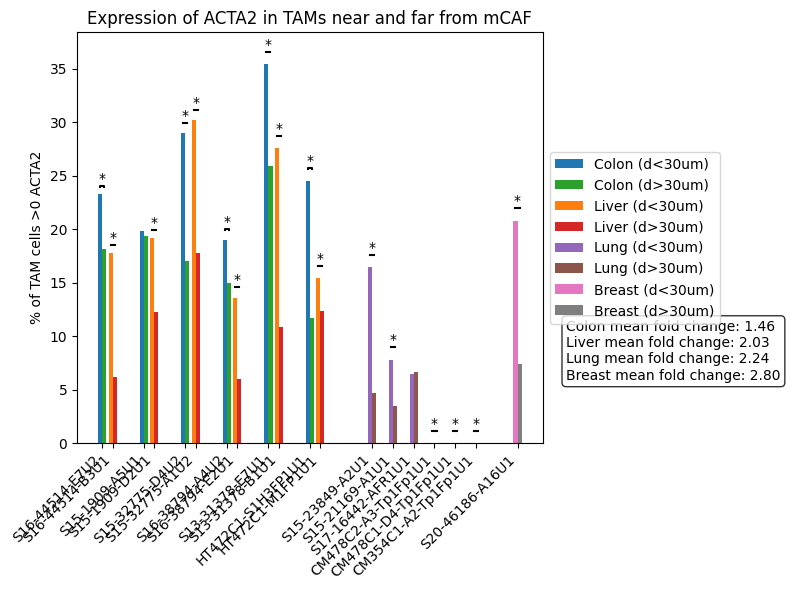

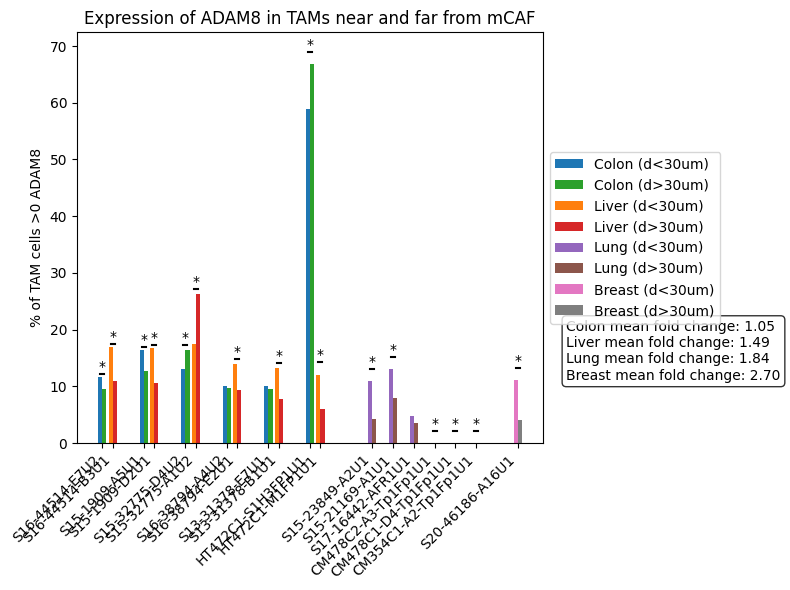

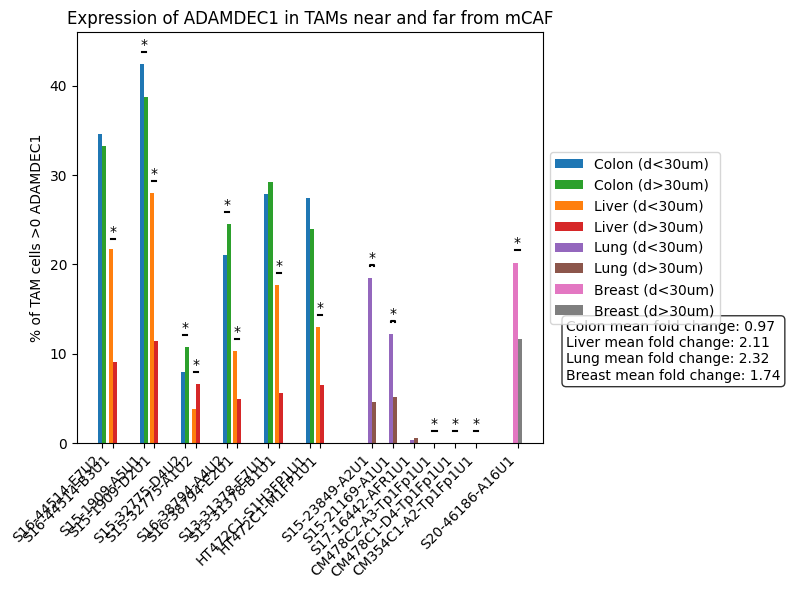

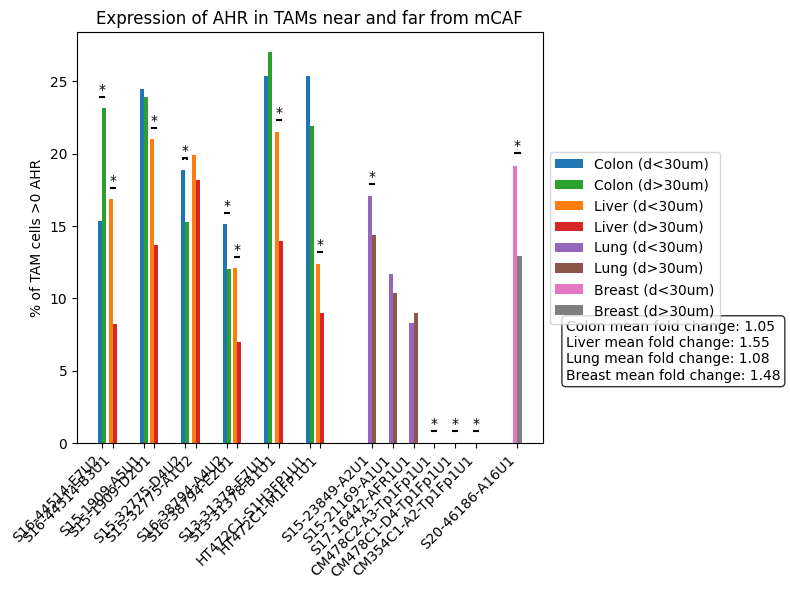

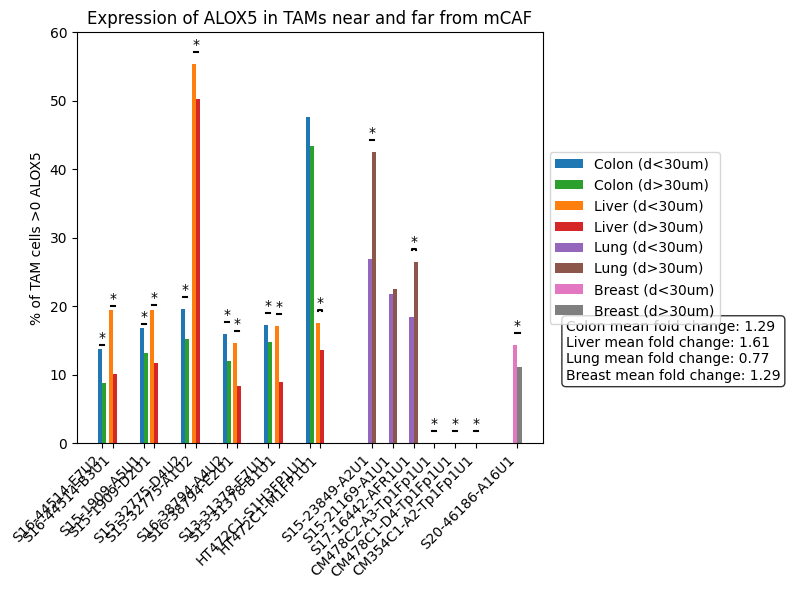

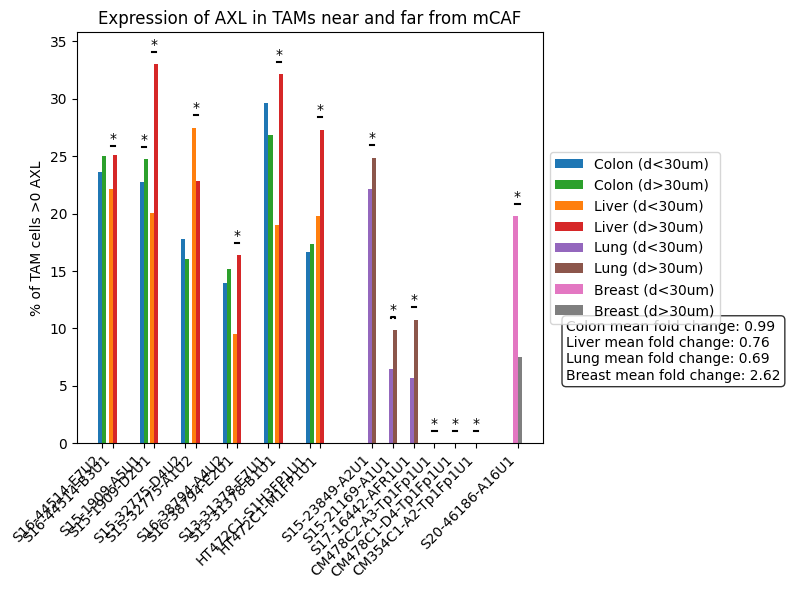

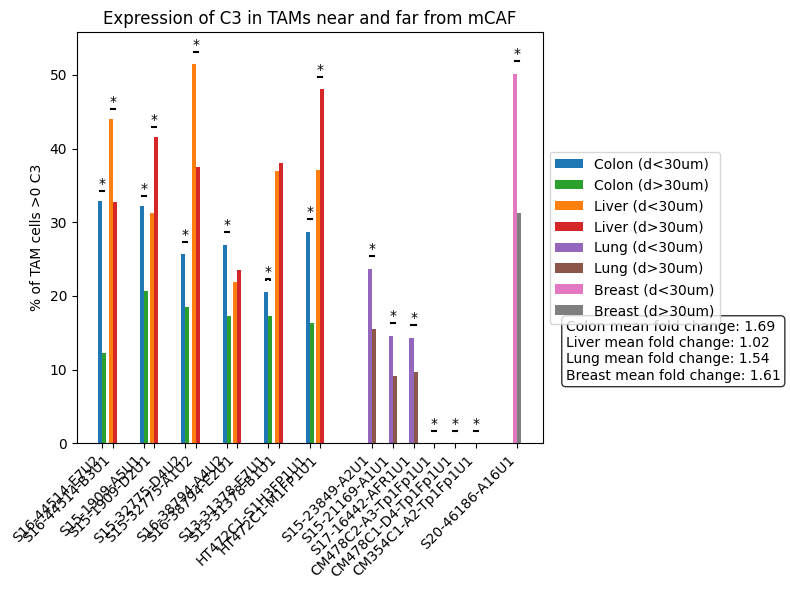

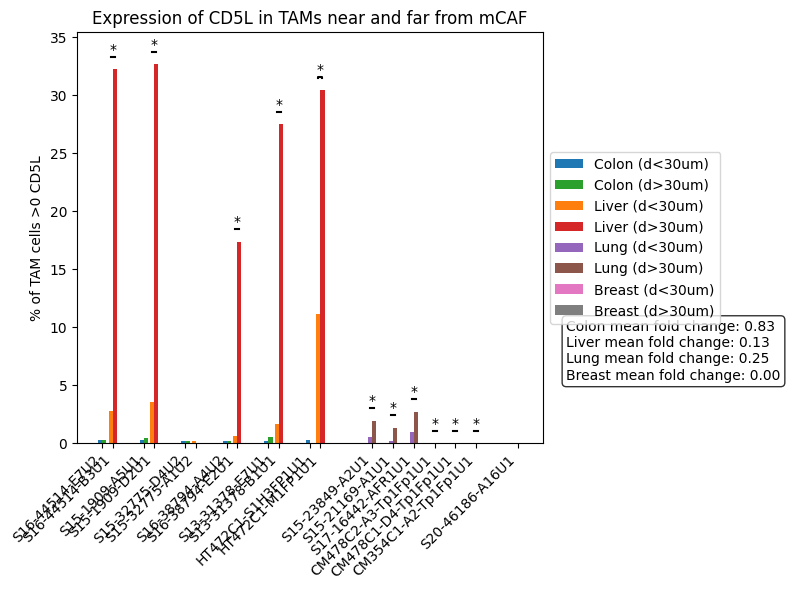

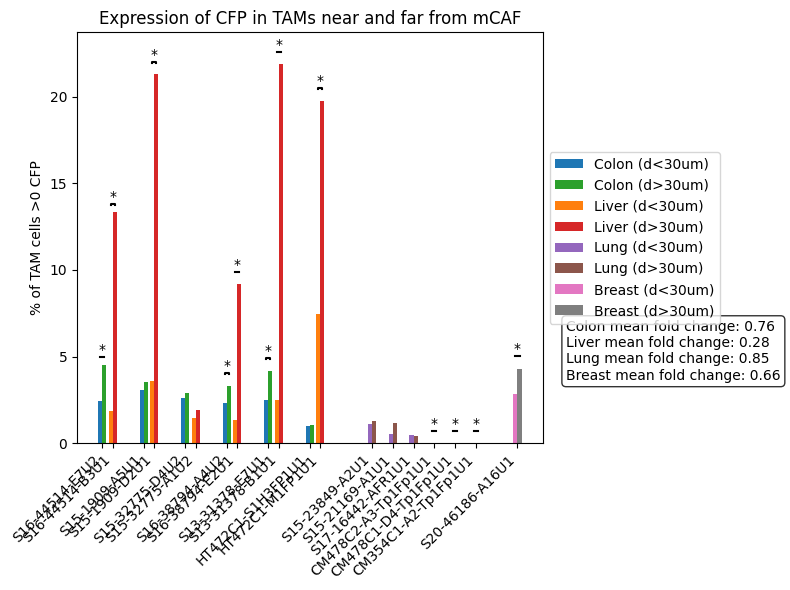

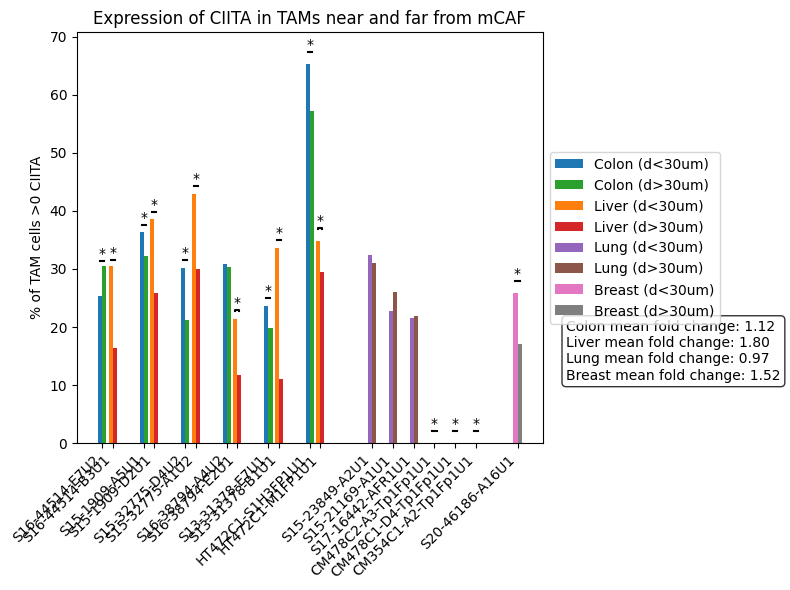

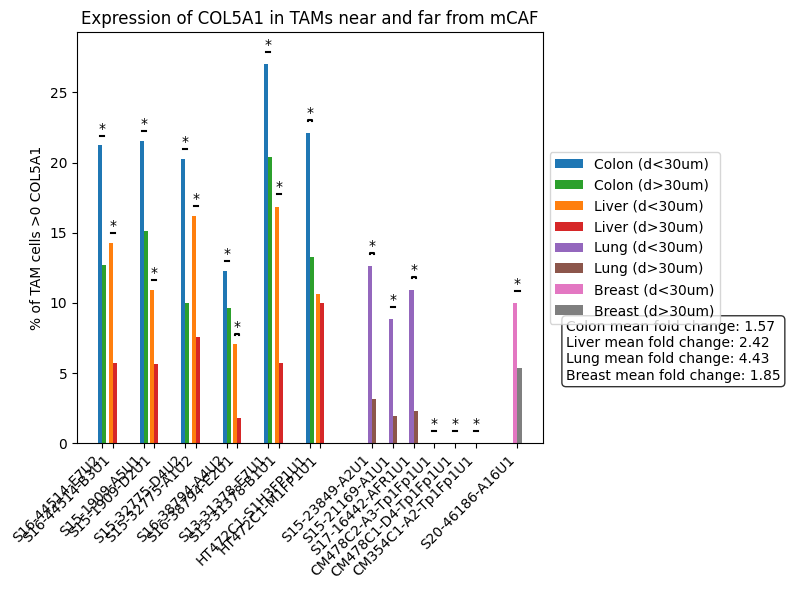

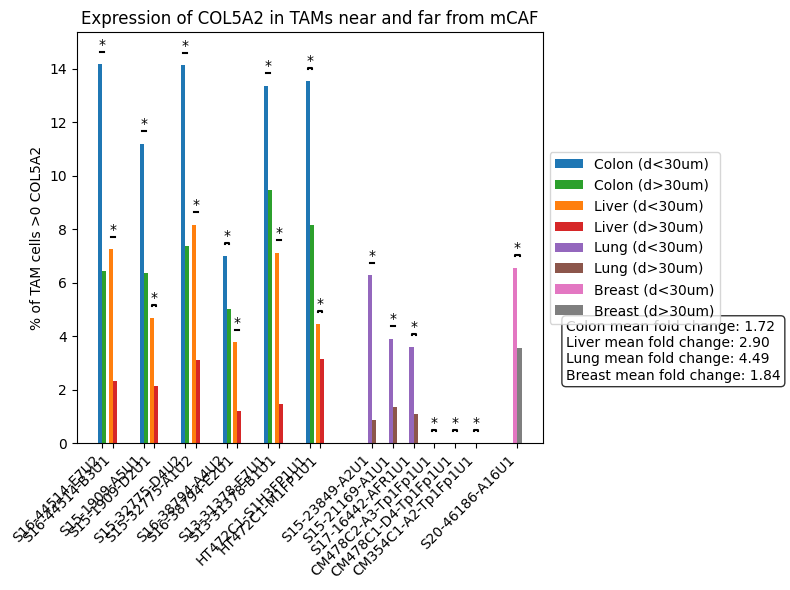

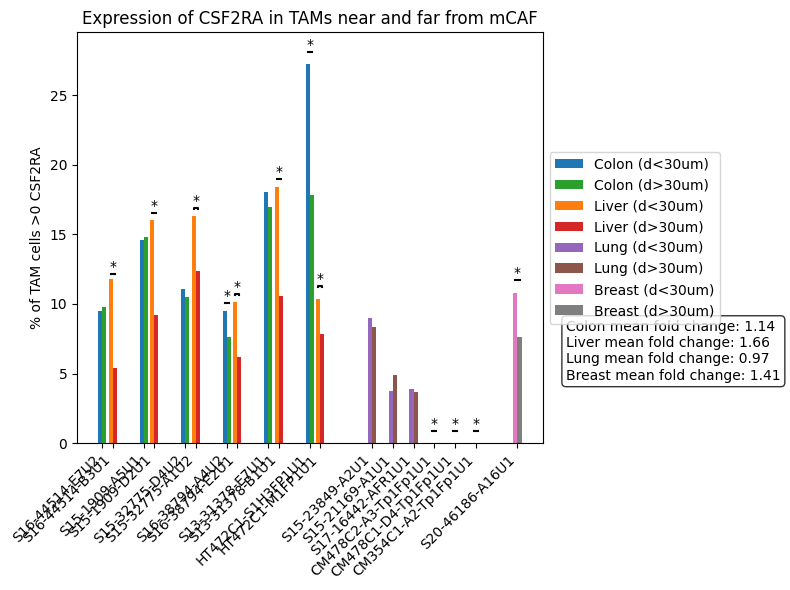

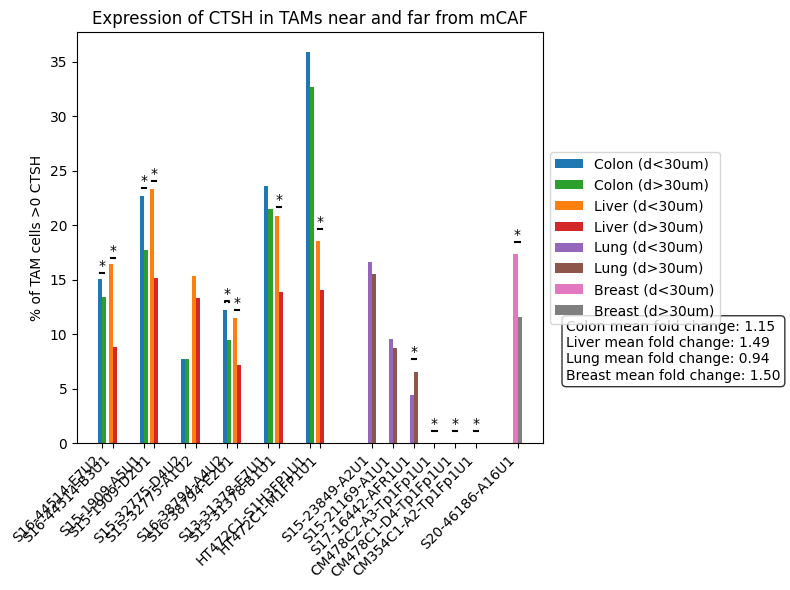

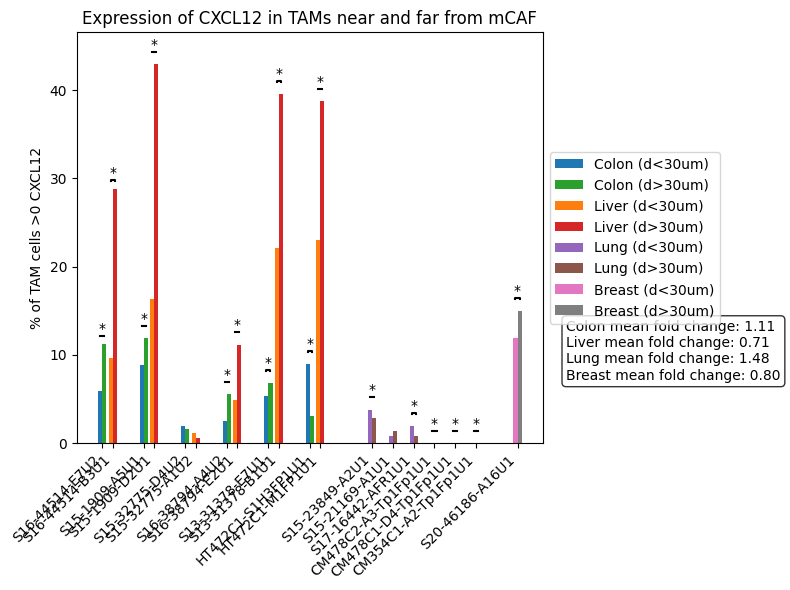

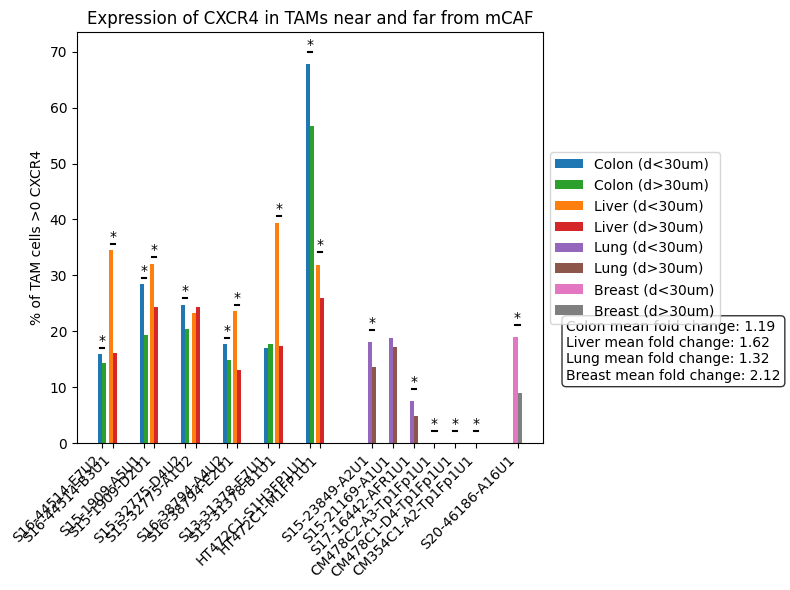

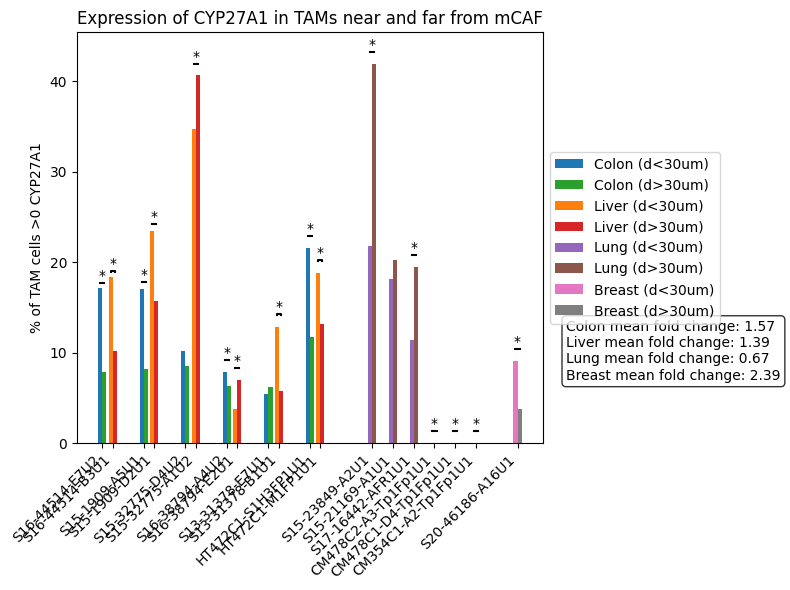

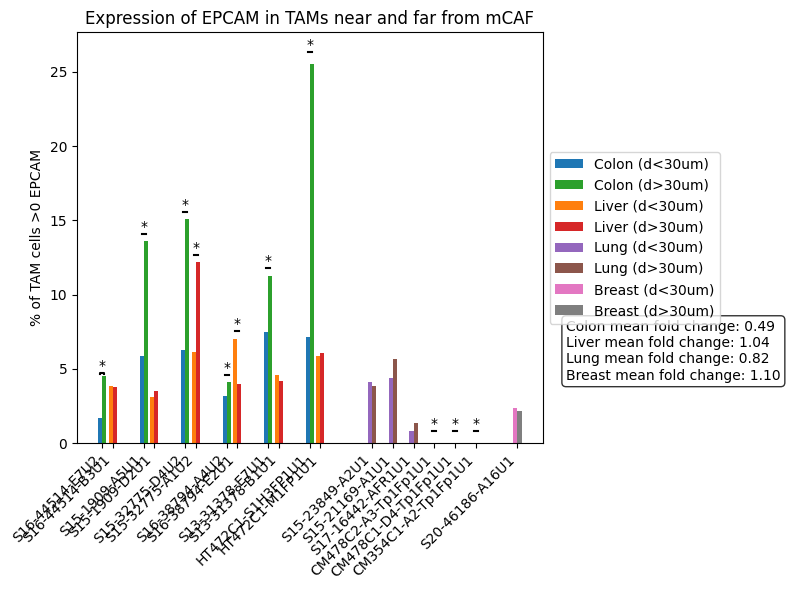

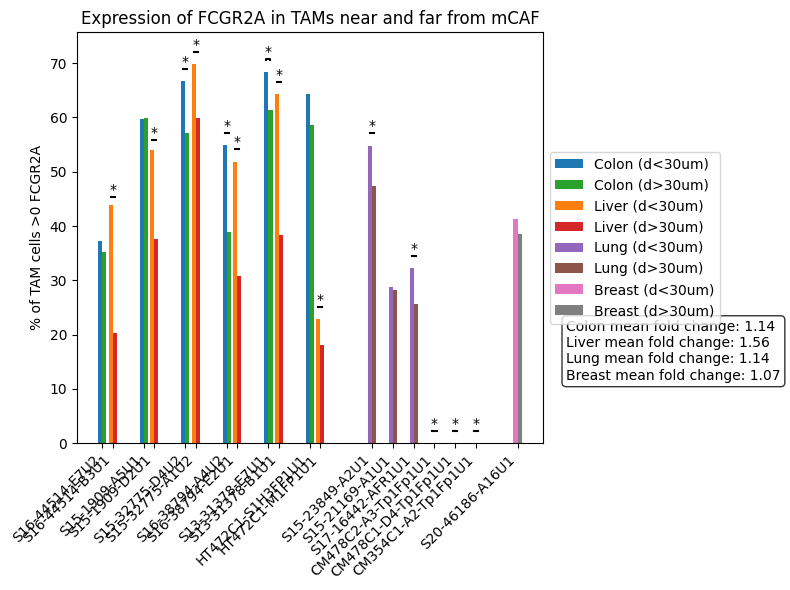

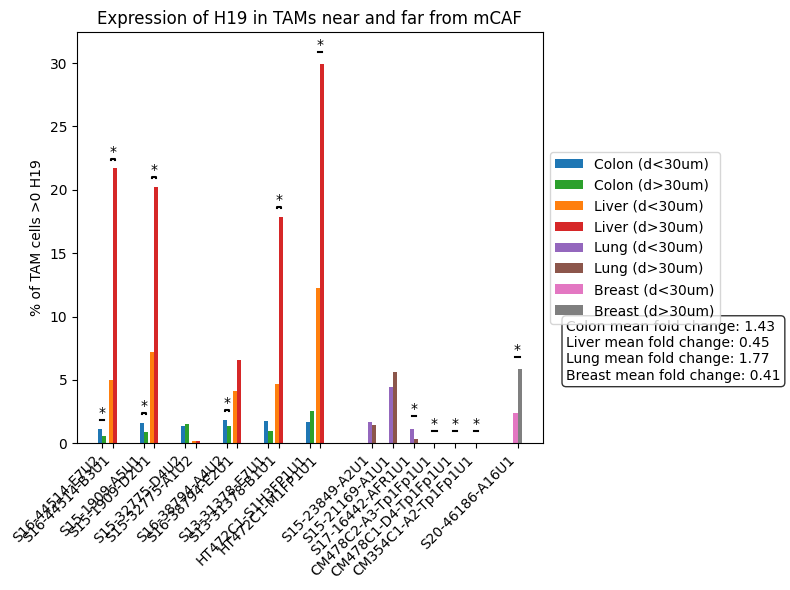

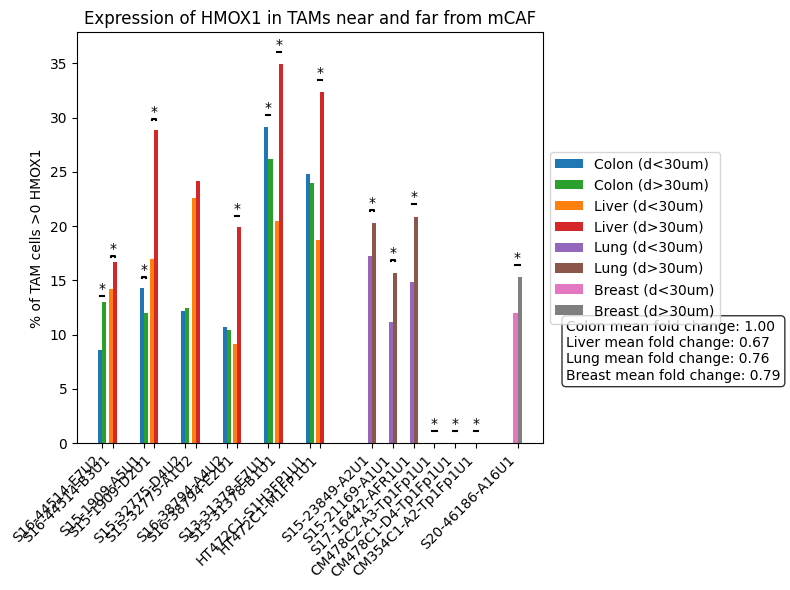

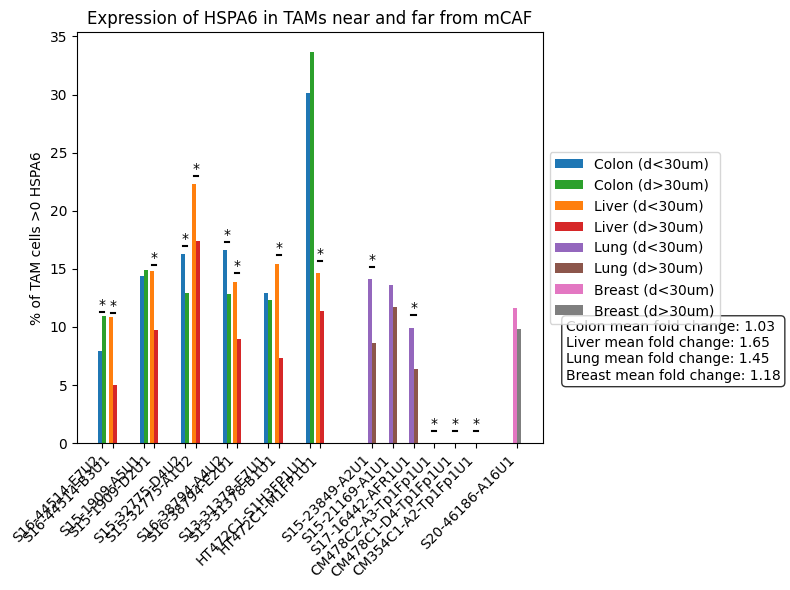

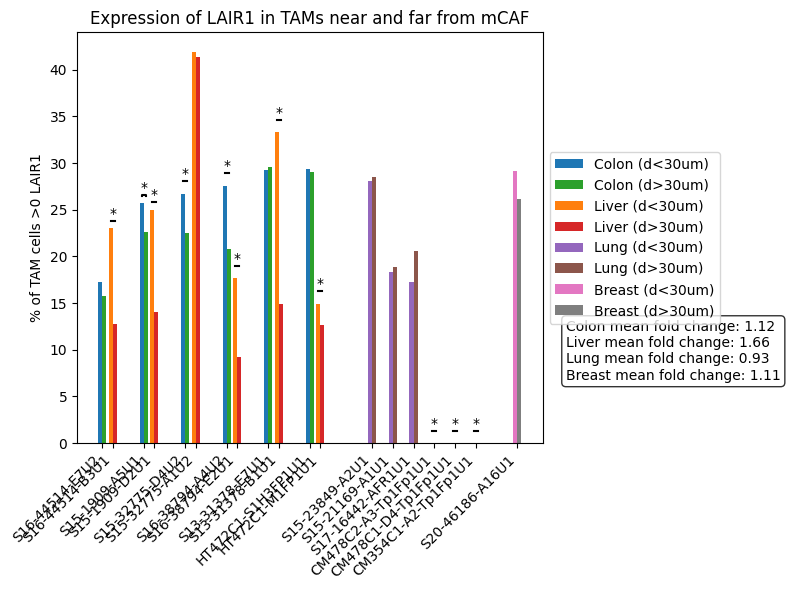

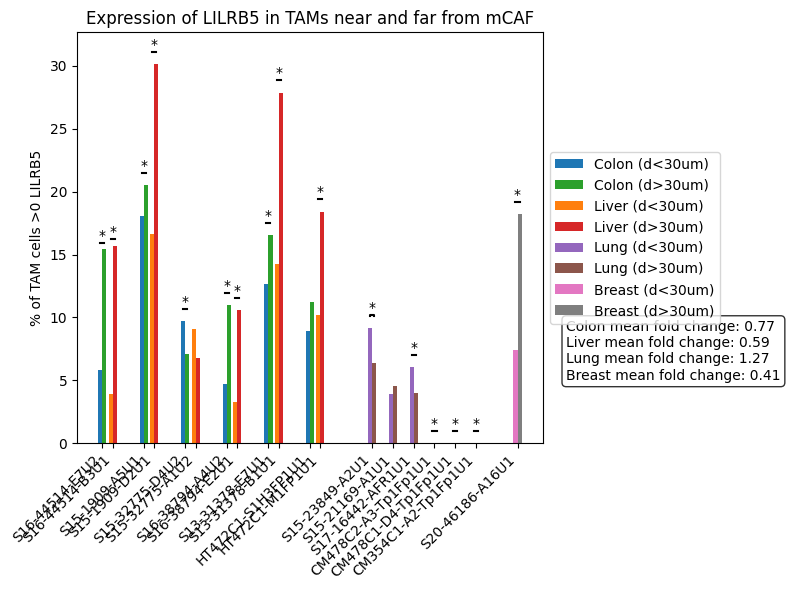

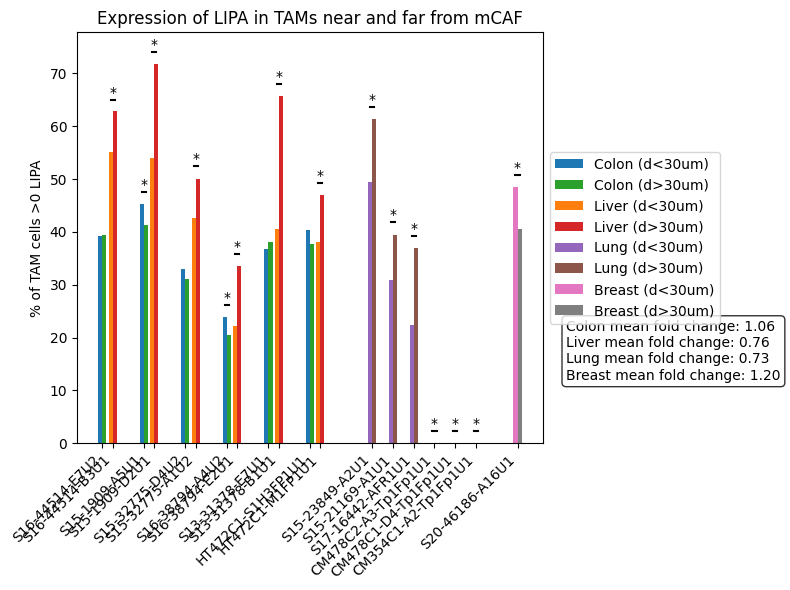

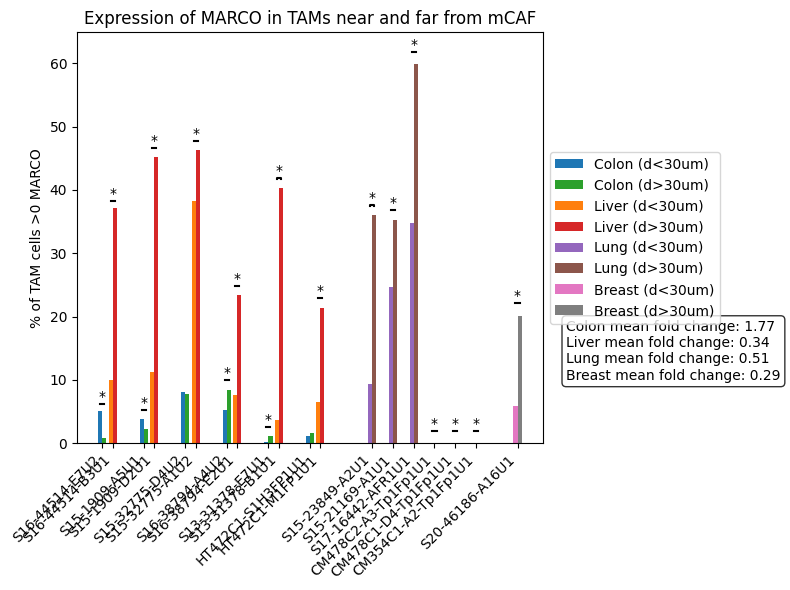

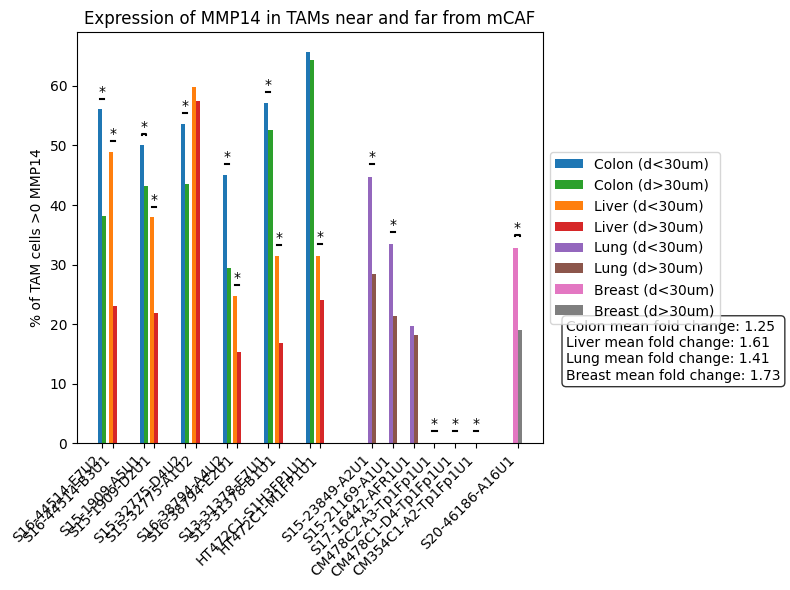

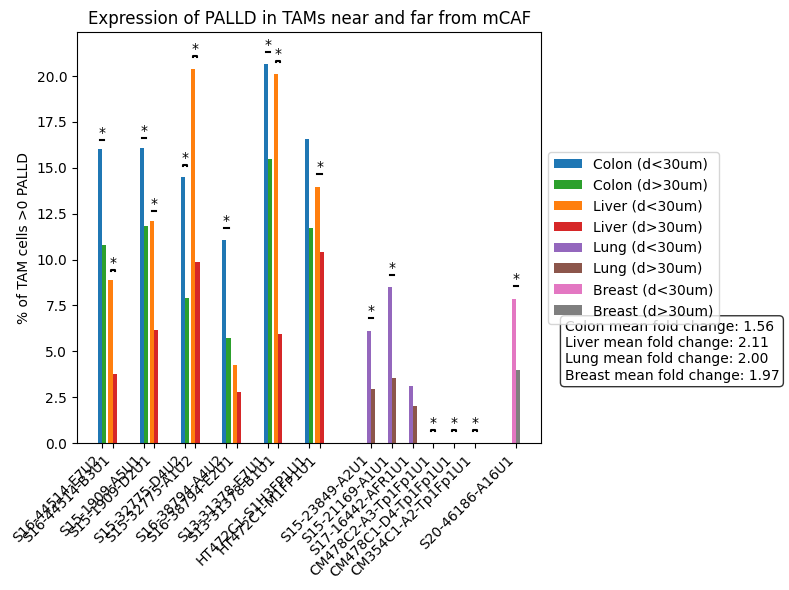

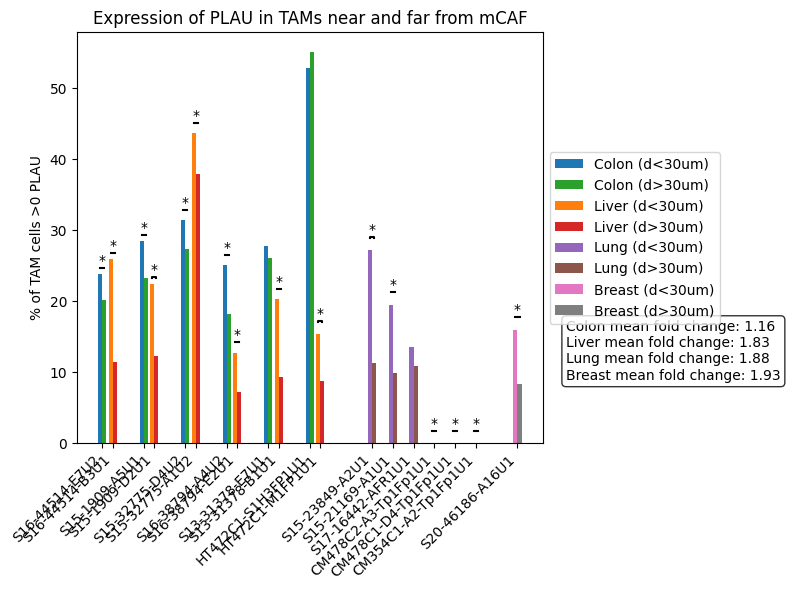

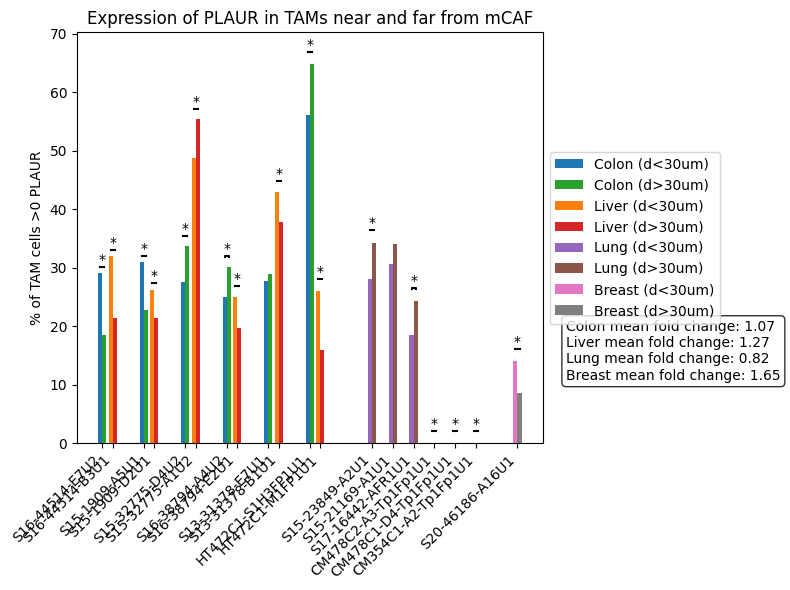

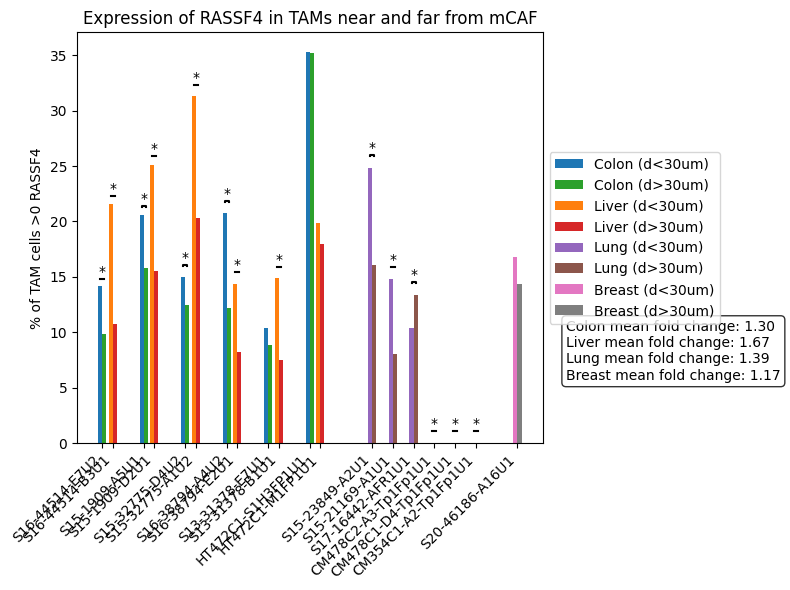

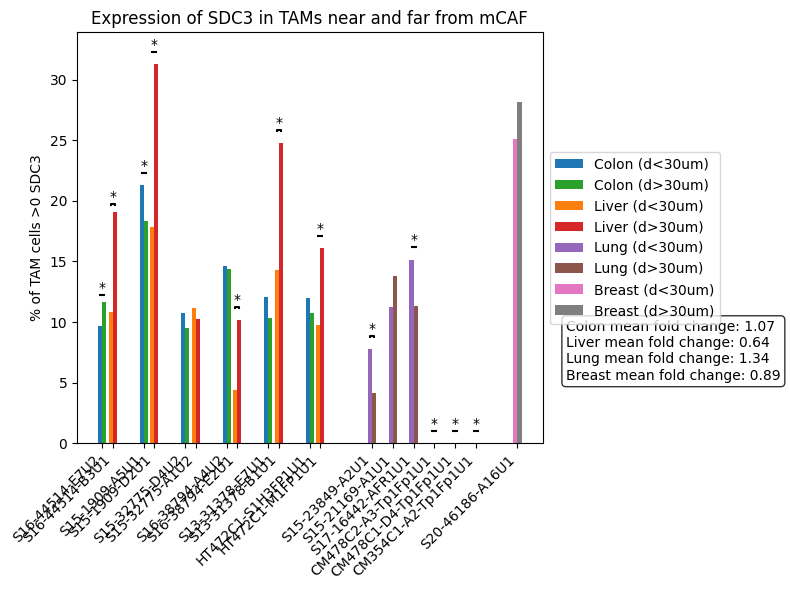

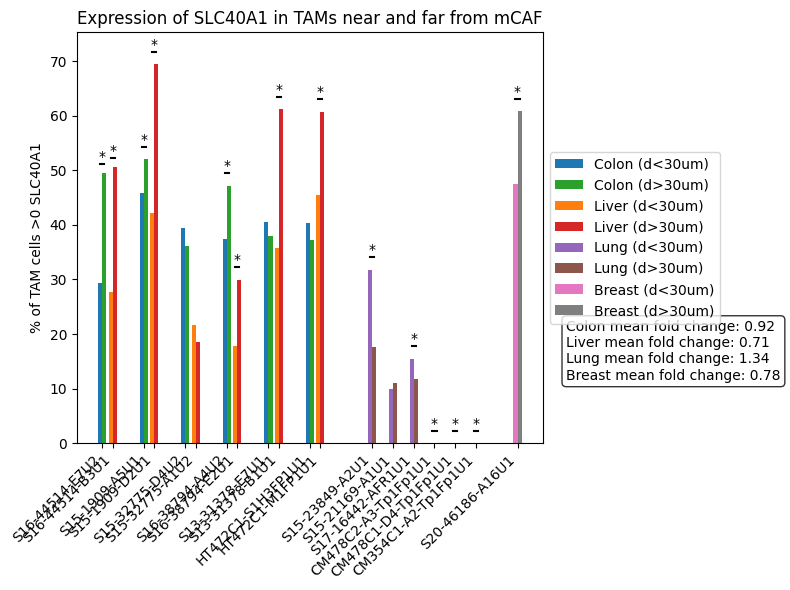

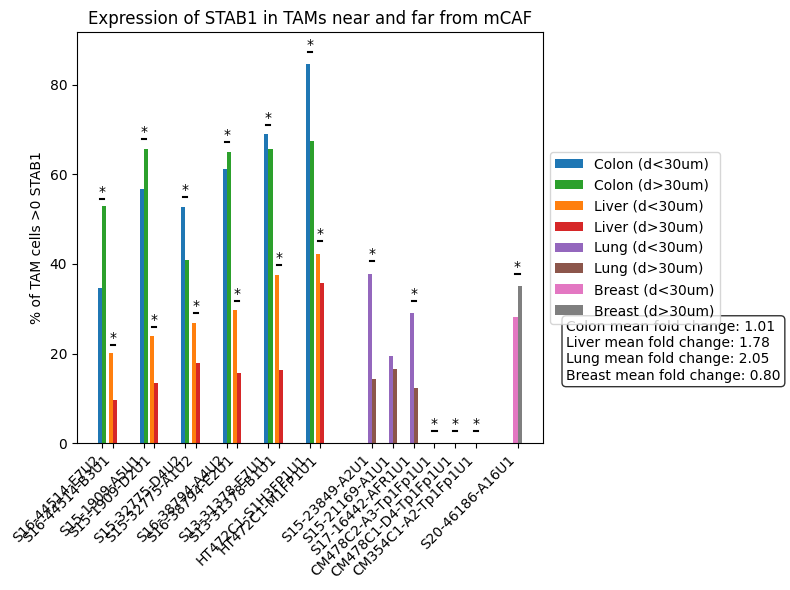

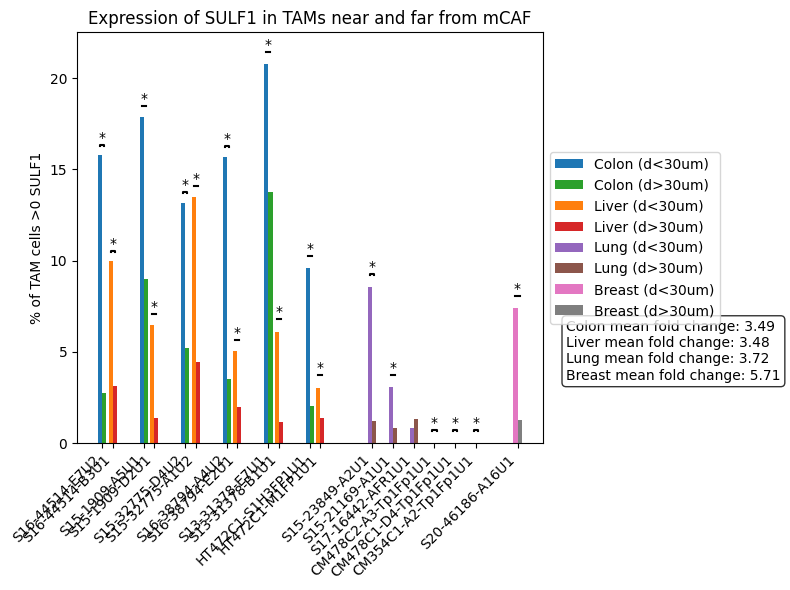

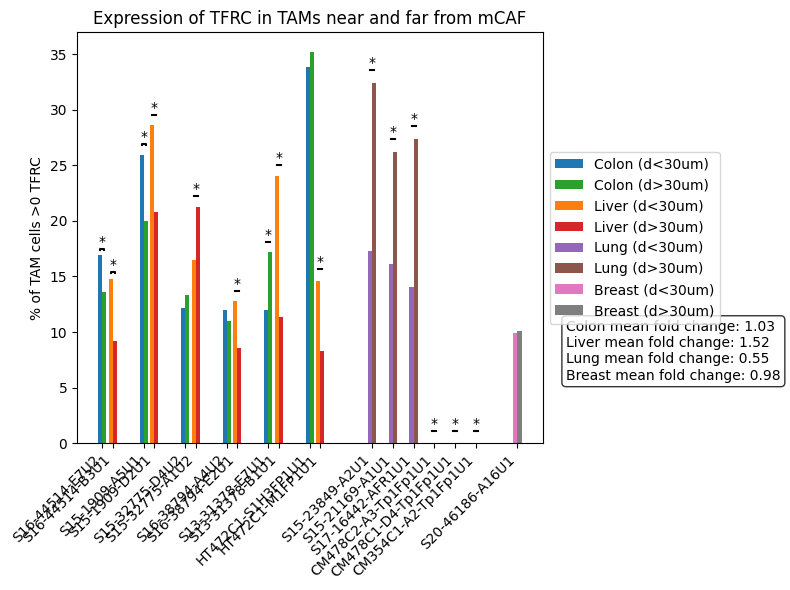

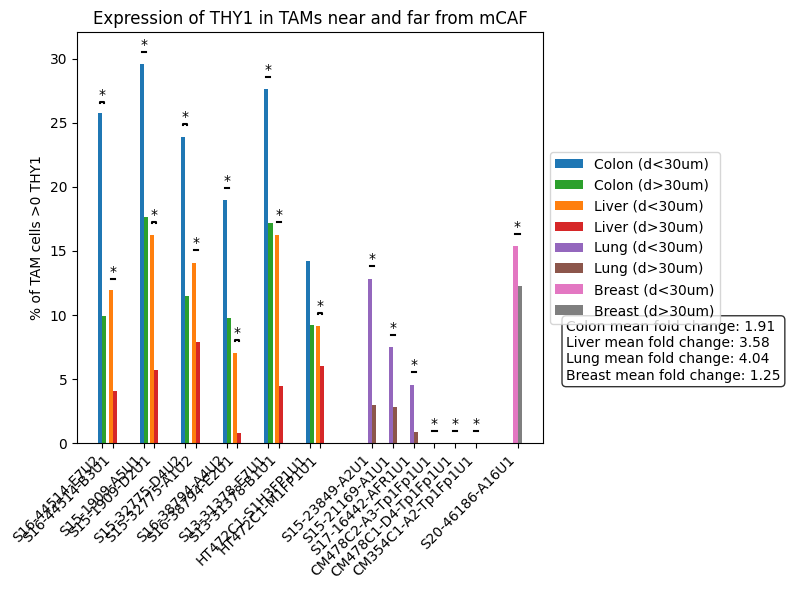

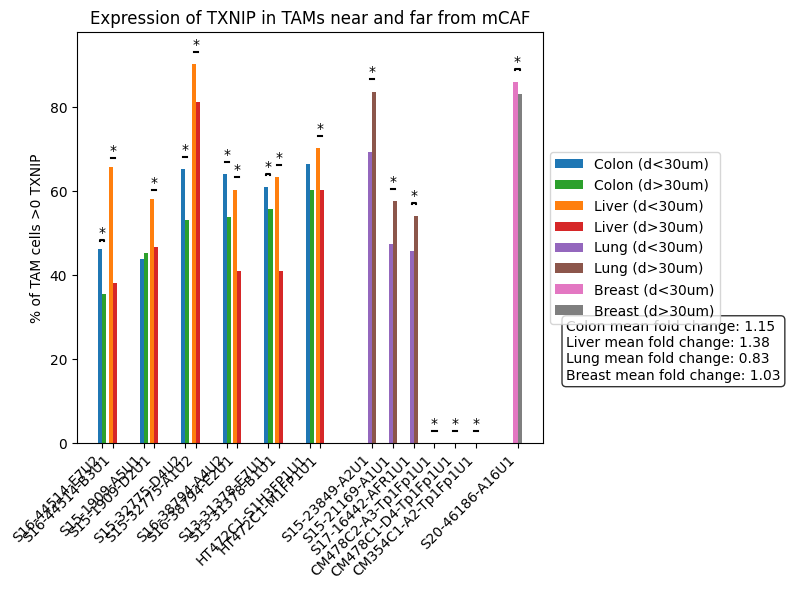

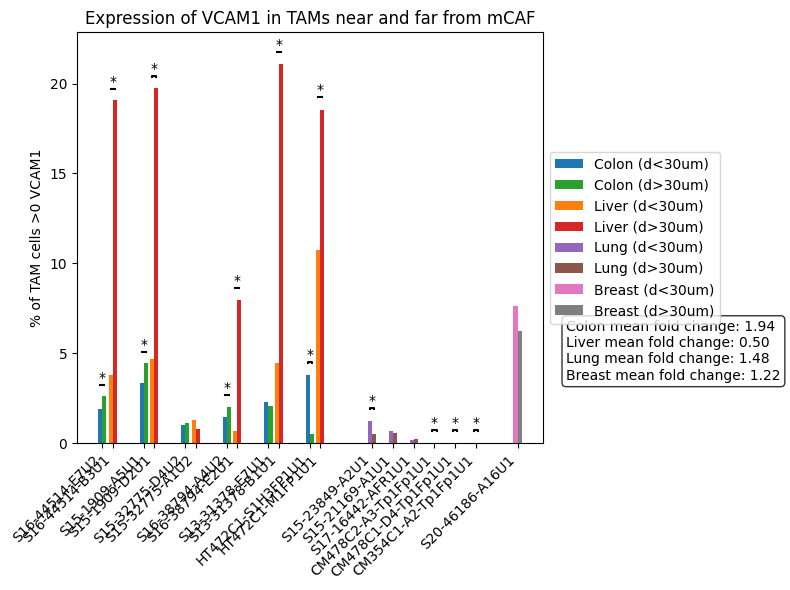

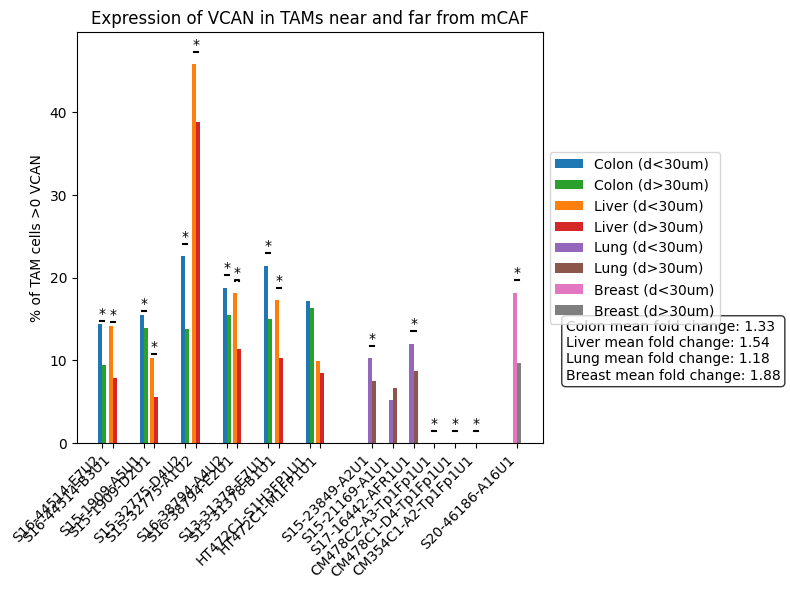

Plots saved in: gene_spatial_analysis/mCAFtoTAM/png_files/
PDF saved as: gene_spatial_analysis/mCAFtoTAM/mCAF_2_TAM.pdf


In [57]:
import os
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

# Define your lists of unpaired samples
lung_ids = ['S15-23849-A2U1', 'S15-21169-A1U1', 'S17-16442-AFR1U1',
            'CM478C2-A3-Tp1Fp1U1', 'CM478C1-D4-Tp1Fp1U1', 'CM354C1-A2-Tp1Fp1U1']
breast_ids = ['S20-46186-A16U1']

sig_thresh = 0.05

def add_significance(ax, x_left, x_right, y, text='*', line_height=0.02):
    """
    Draws a bracket and text (e.g. '*') above two bars that are at x_left and x_right.
    'y' is the vertical coordinate above which the bracket is drawn.
    'line_height' is how high the bracket arms go above 'y'.
    """
    ax.plot([x_left, x_left, x_right, x_right],
            [y, y + line_height, y + line_height, y],
            color='black')
    ax.text((x_left + x_right) / 2, y + line_height, text, ha='center', va='bottom')

# Create output directories
os.makedirs('gene_spatial_analysis', exist_ok=True)
subdir = donor_cell_type.replace(' ','-') + 'to' + receiver_cell_type.replace(' ','-')
os.makedirs(f'gene_spatial_analysis/{subdir}', exist_ok=True)
os.makedirs(f'gene_spatial_analysis/{subdir}/png_files', exist_ok=True)  # For PNGs

# Define the PDF output filename
pdf_filename = os.path.join('gene_spatial_analysis', subdir, cell_type_key + '.pdf')

with PdfPages(pdf_filename) as pdf:
    for gene in hit_genes:
        # Collect data for the current gene
        data = []
        for section_id in section_hit_dict.keys():
            # Example structure: each entry is (gene, val_in, val_out, ... p_val at index 7, etc.)
            hit = [x for x in section_hit_dict[section_id][cell_type_key] if x[0] == gene][0]
            val_in, val_out, p_val = hit[1], hit[2], hit[7]
            data.append([section_id, val_in, val_out, p_val])
        
        data_dict = {row[0]: (row[1], row[2], row[3]) for row in data}
        
        # Create figure & axis
        fig, ax = plt.subplots(figsize=(8, 6))
        
        xtick_positions = []
        xtick_labels = []
        
        # Initialize counters and sums for fold changes
        col_fold_change = 0.0
        liver_fold_change = 0.0
        lung_fold_change = 0.0
        breast_fold_change = 0.0
        
        # We'll track how many valid samples (non-zero denominators) we have per organ,
        # so we can compute an average fold change for each.
        valid_colon = 0
        valid_liver = 0
        valid_lung = 0
        valid_breast = 0
        
        # First, plot Colon–Liver pairs
        bar_width = 0.3
        for i, (colon_label, liver_label) in enumerate(pairs):
            # Retrieve the data for each sample in the pair
            colon_in, colon_out, colon_p_val = data_dict[colon_label]
            liver_in, liver_out, liver_p_val = data_dict[liver_label]

            # x positions for these bars
            x_colon = i * 3.0          # extra spacing so we can fit the lung/breast groups later
            x_liver = i * 3.0 + 0.75   # offset from the colon bars

            # Bar plots: Colon near/far
            ax.bar(x_colon - bar_width/2, colon_in, width=bar_width, color='C0',
                   label='Colon (d<30um)' if i == 0 else "")
            ax.bar(x_colon + bar_width/2, colon_out, width=bar_width, color='C2',
                   label='Colon (d>30um)' if i == 0 else "")

            # Bar plots: Liver near/far
            ax.bar(x_liver - bar_width/2, liver_in, width=bar_width, color='C1',
                   label='Liver (d<30um)' if i == 0 else "")
            ax.bar(x_liver + bar_width/2, liver_out, width=bar_width, color='C3',
                   label='Liver (d>30um)' if i == 0 else "")

            # Significance bracket for Colon
            if colon_p_val < sig_thresh:
                max_height = max(colon_in, colon_out)
                bracket_y = max_height + (0.03 * ax.get_ylim()[1])
                add_significance(ax, x_colon - bar_width/2, x_colon + bar_width/2, bracket_y, text='*')

            # Significance bracket for Liver
            if liver_p_val < sig_thresh:
                max_height = max(liver_in, liver_out)
                bracket_y = max_height + (0.03 * ax.get_ylim()[1])
                add_significance(ax, x_liver - bar_width/2, x_liver + bar_width/2, bracket_y, text='*')

            # Accumulate fold-change calculations for Colon
            if colon_out > 0:
                col_fold_change += (colon_in / colon_out)
                valid_colon += 1

            # Accumulate fold-change calculations for Liver
            if liver_out > 0:
                liver_fold_change += (liver_in / liver_out)
                valid_liver += 1
            
            # Add xticks for these positions
            xtick_positions.extend([x_colon, x_liver])
            xtick_labels.extend([colon_label, liver_label])

        # After pairs are plotted, we move on to the unpaired Lung samples
        # We'll start them after the last pair's bars to avoid overlap
        offset_lung = len(pairs) * 3.0 + 1.5  # 1.5 to push them to the right
        for j, lung_label in enumerate(lung_ids):
            # x position for this lung sample
            x_lung = offset_lung + j * 1.5
            lung_in, lung_out, lung_p_val = data_dict[lung_label]
            
            # Plot lung near/far
            ax.bar(x_lung - bar_width/2, lung_in, width=bar_width, color='C4',
                   label='Lung (d<30um)' if j == 0 else "")
            ax.bar(x_lung + bar_width/2, lung_out, width=bar_width, color='C5',
                   label='Lung (d>30um)' if j == 0 else "")

            # Significance bracket for this lung sample
            if lung_p_val < sig_thresh:
                max_height = max(lung_in, lung_out)
                bracket_y = max_height + (0.03 * ax.get_ylim()[1])
                add_significance(ax, x_lung - bar_width/2, x_lung + bar_width/2, bracket_y, text='*')

            # Fold change
            if lung_out > 0:
                lung_fold_change += (lung_in / lung_out)
                valid_lung += 1

            # Add xtick
            xtick_positions.append(x_lung)
            xtick_labels.append(lung_label)

        # Now plot the single Breast sample(s), if any
        offset_breast = offset_lung + len(lung_ids) * 1.5 + 1.5
        for k, breast_label in enumerate(breast_ids):
            x_breast = offset_breast + k * 1.5
            breast_in, breast_out, breast_p_val = data_dict[breast_label]
            
            # Plot breast near/far
            ax.bar(x_breast - bar_width/2, breast_in, width=bar_width, color='C6',
                   label='Breast (d<30um)' if k == 0 else "")
            ax.bar(x_breast + bar_width/2, breast_out, width=bar_width, color='C7',
                   label='Breast (d>30um)' if k == 0 else "")

            # Significance bracket for this breast sample
            if breast_p_val < sig_thresh:
                max_height = max(breast_in, breast_out)
                bracket_y = max_height + (0.03 * ax.get_ylim()[1])
                add_significance(ax, x_breast - bar_width/2, x_breast + bar_width/2, bracket_y, text='*')

            # Fold change
            if breast_out > 0:
                breast_fold_change += (breast_in / breast_out)
                valid_breast += 1

            # Add xtick
            xtick_positions.append(x_breast)
            xtick_labels.append(breast_label)

        # Finalize x-axis ticks/labels
        ax.set_xticks(xtick_positions)
        ax.set_xticklabels(xtick_labels, rotation=45, ha='right')

        # Compute the average fold change for each organ type (where we had non-zero denominators)
        avg_col_fold_change    = col_fold_change / valid_colon    if valid_colon    > 0 else 0
        avg_liver_fold_change  = liver_fold_change / valid_liver  if valid_liver    > 0 else 0
        avg_lung_fold_change   = lung_fold_change / valid_lung    if valid_lung     > 0 else 0
        avg_breast_fold_change = breast_fold_change / valid_breast if valid_breast  > 0 else 0

        # Labeling & Title
        ax.set_ylabel(f'% of {receiver_cell_type} cells >0 {gene}')
        ax.set_title(f'Expression of {gene} in {receiver_cell_type}s near and far from {donor_cell_type}')
        ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))

        # Show average fold-change text
        textstr = (
            f"Colon mean fold change: {avg_col_fold_change:.2f}\n"
            f"Liver mean fold change: {avg_liver_fold_change:.2f}\n"
            f"Lung mean fold change: {avg_lung_fold_change:.2f}\n"
            f"Breast mean fold change: {avg_breast_fold_change:.2f}"
        )
        ax.text(1.05, 0.3, textstr, transform=ax.transAxes, fontsize=10, va='top',
                bbox=dict(boxstyle='round', facecolor='white', ec='black', alpha=0.8))

        plt.tight_layout()
        plt.show()

        # Save a PNG for this gene (uncomment if you need actual files)
        # png_filename = f'gene_spatial_analysis/{subdir}/png_files/{gene}.png'
        # plt.savefig(png_filename, bbox_inches='tight', dpi=300)

        # Save to PDF
        # pdf.savefig(fig, bbox_inches='tight')
        plt.close(fig)  # Free memory

print(f"Plots saved in: gene_spatial_analysis/{subdir}/png_files/")
print(f"PDF saved as: {pdf_filename}")


In [10]:
gene = "PROX1"
donor_cell_type = "fibroblast_WNT5A"
dist_threshes = np.arange(10,405,10)

# sect_dict = {}
with open("PROX1_section_dict.pkl", "rb") as f:
    sect_dict = pickle.load(f)
    
for section_id in tqdm.tqdm(section_ids):
    print(section_id)
    if section_id in sect_dict.keys():
        print(section_id, "already computed. Skipping...")
        continue

    seurat_table = pd.read_csv(BASE_DIR + 'seurat_to_python/' + section_id + '.csv', low_memory=False)

    receiver_cells = seurat_table[seurat_table["all_cell_type"].isin(tumor_cell_types)]
    donor_cells = seurat_table[seurat_table["all_cell_type"]==donor_cell_type]

    if receiver_cells.shape[0] == 0 or donor_cells.shape[0] == 0:
        tot_in = 0
        tot_out = 0
    else:
        rec_coords = np.stack((receiver_cells["x"].values, receiver_cells["y"].values))
        don_coords = np.stack((donor_cells["x"].values, donor_cells["y"].values))
        don_tree = cKDTree(don_coords.T)
        distances, indices = don_tree.query(rec_coords.T, k=1)

    dist_dict = {}
    for dist_thresh in dist_threshes:
        rec_coords = np.stack((receiver_cells["x"].values, receiver_cells["y"].values))
        don_coords = np.stack((donor_cells["x"].values, donor_cells["y"].values))
        don_tree = cKDTree(don_coords.T)
        distances, indices = don_tree.query(rec_coords.T, k=1)
        cells_in = np.where(distances<dist_thresh)
        tot_in = cells_in[0].shape[0]
        cells_out = np.where(distances>dist_thresh)
        tot_out = cells_out[0].shape[0]
        gene_array = np.asarray(receiver_cells[gene])
        num_inwards = int(sum(gene_array[cells_in]>0))
        num_outwards = int(sum(gene_array[cells_out]>0))

        if tot_out>0:
            prop_inwards = num_inwards/tot_in*100
        else:
            prop_inwards = "NA"            
        if tot_out>0:
            prop_outwards = num_outwards/tot_out*100
        else:
            prop_outwards = "NA"

        dist_dict[int(dist_thresh)] = [prop_inwards, prop_outwards, num_inwards, num_outwards, tot_in, tot_out]

    sect_dict[section_id] = dist_dict

    with open("PROX1_section_dict.pkl", "wb") as f:
        pickle.dump(sect_dict, f)

  0%|                                                                                                                                                                  | 0/21 [00:00<?, ?it/s]

S16-44514-E7U2
S16-44514-E7U2 already computed. Skipping...
S16-44514-B3U1
S16-44514-B3U1 already computed. Skipping...
S15-23849-A2U1
S15-23849-A2U1 already computed. Skipping...
S15-21169-A1U1
S15-21169-A1U1 already computed. Skipping...
S15-1909-D2U1
S15-1909-D2U1 already computed. Skipping...
S15-1909-A5U1
S15-1909-A5U1 already computed. Skipping...
S15-32775-D4U2
S15-32775-D4U2 already computed. Skipping...
S16-38794-E2U1
S16-38794-E2U1 already computed. Skipping...
S15-32775-A1U2
S15-32775-A1U2 already computed. Skipping...
S16-38794-A4U2
S16-38794-A4U2 already computed. Skipping...
HT413C1-Th1K2A1U2
HT413C1-Th1K2A1U2 already computed. Skipping...
S13-31378-B1U1


 57%|███████████████████████████████████████████████████████████████████████████████████████▍                                                                 | 12/21 [07:10<05:22, 35.85s/it]

S13-31378-E7U1


 62%|██████████████████████████████████████████████████████████████████████████████████████████████▋                                                          | 13/21 [13:02<09:16, 69.53s/it]

HT472C1-S1H3FP1U1


... (11 outputs left out)

CM478C1-D4-Tp1Fp1U1


 95%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▊       | 20/21 [39:54<03:59, 239.76s/it]

CM354C1-A2-Tp1Fp1U1


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 21/21 [41:21<00:00, 118.15s/it]


In [11]:
sect_dict.keys()

dict_keys(['S16-44514-E7U2', 'S16-44514-B3U1', 'S15-23849-A2U1', 'S15-21169-A1U1', 'S15-1909-D2U1', 'S15-1909-A5U1', 'S15-32775-D4U2', 'S16-38794-E2U1', 'S15-32775-A1U2', 'S16-38794-A4U2', 'HT413C1-Th1K2A1U2', 'S13-31378-B1U1', 'S13-31378-E7U1', 'HT472C1-S1H3FP1U1', 'HT472C1-M1FP1U1', 'S17-16442-AFR1U1', 'S13-18424-B5U1', 'S20-46186-A16U1', 'CM478C2-A3-Tp1Fp1U1', 'CM478C1-D4-Tp1Fp1U1', 'CM354C1-A2-Tp1Fp1U1'])

In [ ]:
# with open("tumor_section_hit_dict.pkl", "rb") as f:
#     section_hit_dict = pickle.load(f)

In [ ]:
min_percent = 5

fold_change_data = []

for gene in hit_genes:
    # Collect data for the current gene
    data = []
    for section_id in section_hit_dict.keys():
        # Each entry is (gene, val_in, val_out, ..., p_val at index 7, etc.)
        hit = [x for x in section_hit_dict[section_id][cell_type_key] if x[0] == gene][0]
        val_in, val_out, p_val = hit[1], hit[2], hit[7]
        data.append([section_id, val_in, val_out, p_val])

    # Make a lookup dictionary: section_id -> (val_in, val_out, p_val)
    data_dict = {row[0]: (row[1], row[2], row[3]) for row in data}

    # Initialize counters and sums for fold changes
    col_fold_change = 0.0
    liver_fold_change = 0.0
    lung_fold_change = 0.0
    breast_fold_change = 0.0

    # Track how many valid samples (non-zero denominators) we have per organ
    valid_colon = 0
    valid_liver = 0
    valid_lung = 0
    valid_breast = 0

    # Track ALL in/out values, to see if any surpass min_percent
    colon_in_out_values = []
    liver_in_out_values = []
    lung_in_out_values  = []
    breast_in_out_values= []

    # Calculate fold changes for Colon–Liver pairs
    for i, (colon_label, liver_label) in enumerate(pairs):
        colon_in, colon_out, colon_p_val  = data_dict[colon_label]
        liver_in, liver_out, liver_p_val  = data_dict[liver_label]

        # Collect raw values for checking min_percent
        colon_in_out_values.extend([colon_in, colon_out])
        liver_in_out_values.extend([liver_in, liver_out])

        # Accumulate fold-change calculations for Colon
        if colon_out > 0:
            col_fold_change += (colon_in / colon_out)
            valid_colon += 1

        # Accumulate fold-change calculations for Liver
        if liver_out > 0:
            liver_fold_change += (liver_in / liver_out)
            valid_liver += 1
    
    # Calculate fold changes for unpaired Lung samples
    for lung_label in lung_ids:
        lung_in, lung_out, lung_p_val = data_dict[lung_label]
        lung_in_out_values.extend([lung_in, lung_out])
        if lung_out > 0:
            lung_fold_change += (lung_in / lung_out)
            valid_lung += 1
    
    # Calculate fold changes for unpaired Breast samples
    for breast_label in breast_ids:
        breast_in, breast_out, breast_p_val = data_dict[breast_label]
        breast_in_out_values.extend([breast_in, breast_out])
        if breast_out > 0:
            breast_fold_change += (breast_in / breast_out)
            valid_breast += 1
    
    # Compute the average fold changes 
    # If no samples for a particular organ -> 0 or "NA" is your choice.
    avg_col_fold_change    = col_fold_change / valid_colon    if valid_colon    > 0 else 0
    avg_liver_fold_change  = liver_fold_change / valid_liver  if valid_liver    > 0 else 0
    avg_lung_fold_change   = lung_fold_change / valid_lung    if valid_lung     > 0 else 0
    avg_breast_fold_change = breast_fold_change / valid_breast if valid_breast  > 0 else 0

    # --- Check if all in/out values for each organ are below min_percent --- #
    # If so, set the average fold change to "NA"
    if colon_in_out_values and max(colon_in_out_values) < min_percent:
        avg_col_fold_change = "NA"
    if liver_in_out_values and max(liver_in_out_values) < min_percent:
        avg_liver_fold_change = "NA"
    if lung_in_out_values and max(lung_in_out_values) < min_percent:
        avg_lung_fold_change = "NA"
    if breast_in_out_values and max(breast_in_out_values) < min_percent:
        avg_breast_fold_change = "NA"
    
    # Append the fold change data for this gene:
    fold_change_data.append([
        gene,
        avg_col_fold_change,
        avg_liver_fold_change,
        avg_lung_fold_change,
        avg_breast_fold_change
    ])

# Example printout of the data:
for row in fold_change_data:
    gene, col_fc, liver_fc, lung_fc, breast_fc = row
    print(f"Gene: {gene}")
    print(f"  Colon mean fold change: {col_fc}")
    print(f"  Liver mean fold change: {liver_fc}")
    print(f"  Lung mean fold change: {lung_fc}")
    print(f"  Breast mean fold change: {breast_fc}")
    print()


In [56]:
colon_fold_changes = []
for dist_thresh in sect_dict[list(sect_dict.keys())[0]].keys():
    fold_changes = []
    for section_id in colon_ids:
        prop_inwards, prop_outwards, num_inwards, num_outwards, tot_in, tot_out = sect_dict[section_id][dist_thresh]
        if prop_outwards!="NA" and prop_outwards>0:
            fold_changes.append(prop_inwards/prop_outwards)
    colon_fold_changes.append([dist_thresh, float(np.mean(fold_changes))])

liver_fold_changes = []
for dist_thresh in sect_dict[list(sect_dict.keys())[0]].keys():
    fold_changes = []
    for section_id in liver_ids:
        prop_inwards, prop_outwards, num_inwards, num_outwards, tot_in, tot_out = sect_dict[section_id][dist_thresh]
        if prop_outwards!="NA" and prop_outwards>0:
            fold_changes.append(prop_inwards / prop_outwards)
    liver_fold_changes.append([dist_thresh, float(np.mean(fold_changes))])

lung_fold_changes = []
for dist_thresh in sect_dict[list(sect_dict.keys())[0]].keys():
    fold_changes = []
    for section_id in lung_ids:
        prop_inwards, prop_outwards, num_inwards, num_outwards, tot_in, tot_out = sect_dict[section_id][dist_thresh]
        if prop_outwards!="NA" and prop_outwards > 0:
            fold_changes.append(prop_inwards / prop_outwards)

    lung_fold_changes.append([dist_thresh, float(np.mean(fold_changes))])

breast_fold_changes = []
for dist_thresh in sect_dict[list(sect_dict.keys())[0]].keys():
    fold_changes = []
    for section_id in breast_ids:
        prop_inwards, prop_outwards, num_inwards, num_outwards, tot_in, tot_out = sect_dict[section_id][dist_thresh]
        if prop_outwards != "NA" and prop_outwards > 0:
            fold_changes.append(prop_inwards / prop_outwards)

    breast_fold_changes.append([dist_thresh, float(np.mean(fold_changes))])


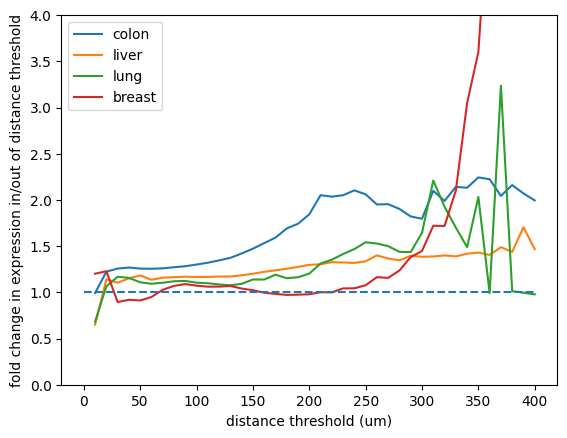

In [81]:
plt.plot([x[0] for x in colon_fold_changes], [x[1] for x in colon_fold_changes], label='colon')
plt.plot([x[0] for x in liver_fold_changes], [x[1] for x in liver_fold_changes], label='liver')
plt.plot([x[0] for x in lung_fold_changes], [x[1] for x in lung_fold_changes], label='lung')
plt.plot([x[0] for x in breast_fold_changes], [x[1] for x in breast_fold_changes], label='breast')
plt.ylim(0,4)
plt.hlines(1,0,400, linestyle='--')
plt.xlabel('distance threshold (um)')
plt.ylabel('fold change in expression in/out of distance threshold')
plt.legend()
plt.savefig('fold_changes.png', dpi=300)

In [65]:
num_outwards

2

In [69]:
pd

<module 'pandas' from '/diskmnt/Projects/Users/aplante/anaconda3/envs/Morphcia/lib/python3.13/site-packages/pandas/__init__.py'>

In [68]:
sect_dict.keys()

dict_keys(['S16-44514-E7U2', 'S16-44514-B3U1', 'S15-23849-A2U1', 'S15-21169-A1U1', 'S15-1909-D2U1', 'S15-1909-A5U1', 'S15-32775-D4U2', 'S16-38794-E2U1', 'S15-32775-A1U2', 'S16-38794-A4U2', 'HT413C1-Th1K2A1U2', 'S13-31378-B1U1', 'S13-31378-E7U1', 'HT472C1-S1H3FP1U1', 'HT472C1-M1FP1U1', 'S17-16442-AFR1U1', 'S13-18424-B5U1', 'S20-46186-A16U1', 'CM478C2-A3-Tp1Fp1U1', 'CM478C1-D4-Tp1Fp1U1', 'CM354C1-A2-Tp1Fp1U1'])

In [82]:
import pandas as pd

section_id = 'S16-44514-B3U1'

rows = []
for dist_thresh in sect_dict[list(sect_dict.keys())[0]].keys():
    prop_inwards, prop_outwards, num_inwards, num_outwards, tot_in, tot_out = sect_dict[section_id][dist_thresh]
    
    row_dict = {
        "dist_thresh": dist_thresh,
        "prop_in": prop_inwards,
        "prop_out": prop_outwards,
        "+_in": num_inwards,
        "+_out": num_outwards,
        "tot_in": tot_in,
        "tot_out": tot_out
    }
    rows.append(row_dict)

df = pd.DataFrame(rows)

# Move 'dist_thresh' to the index (row labels)
df.set_index('dist_thresh', inplace=True)

# Now dist_thresh is the index, and the DataFrame no longer has a separate dist_thresh column
print(df)


               prop_in   prop_out   +_in  +_out  tot_in  tot_out
dist_thresh                                                     
10           11.521418  14.804977     78  34389     677   232280
20           15.737334  14.765971   1112  33355    7066   225891
30           17.379343  14.533454   3727  30740   21445   211512
40           17.813610  14.137839   7424  27043   41676   191281
50           17.721343  13.666621  11493  22974   64854   168103
60           17.497449  13.149406  15431  19036   88190   144767
70           17.095942  12.733518  18824  15643  110108   122849
80           16.804444  12.283498  21751  12716  129436   103521
90           16.520300  11.888321  24154  10313  146208    86749
100          16.257954  11.579236  26035   8432  160137    72820
110          16.054310  11.291213  27515   6952  171387    61570
120          15.898141  11.013501  28675   5792  180367    52590
130          15.758471  10.813551  29561   4906  187588    45369
140          15.636484  1

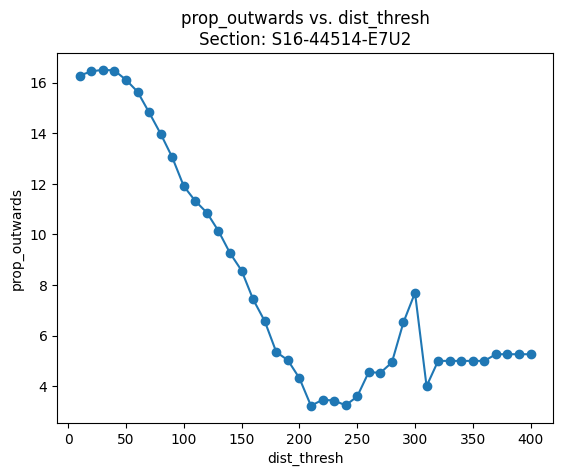

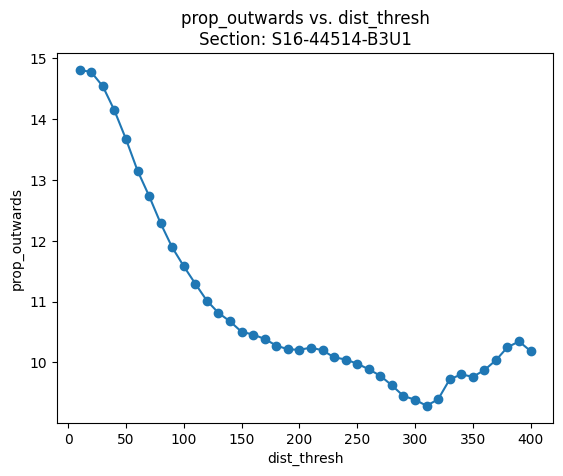

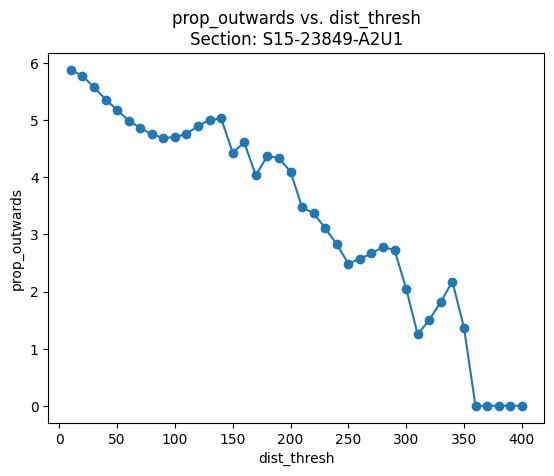

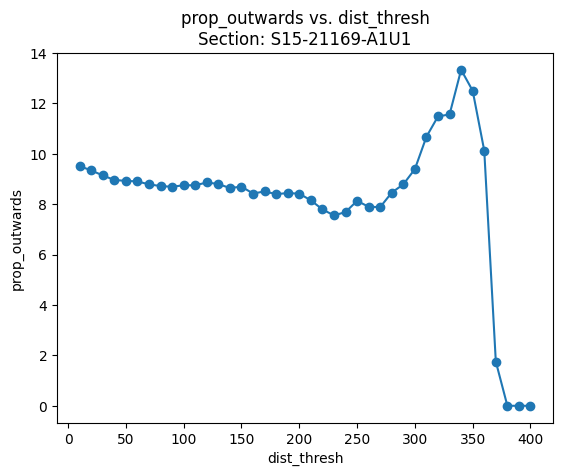

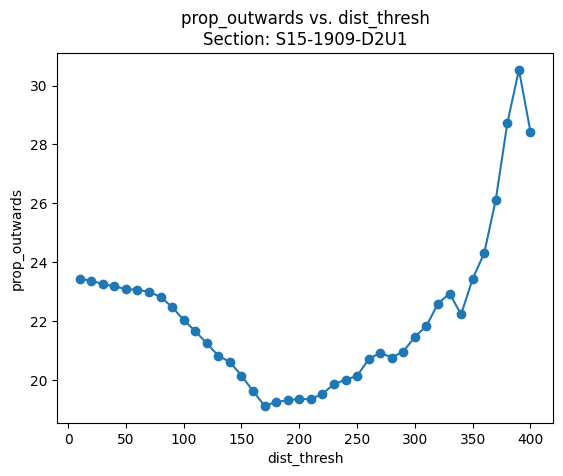

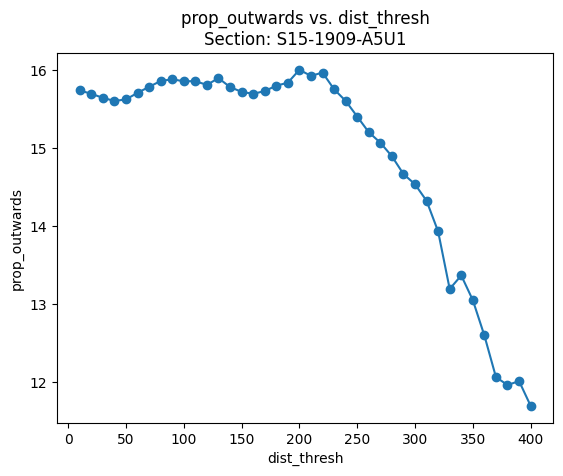

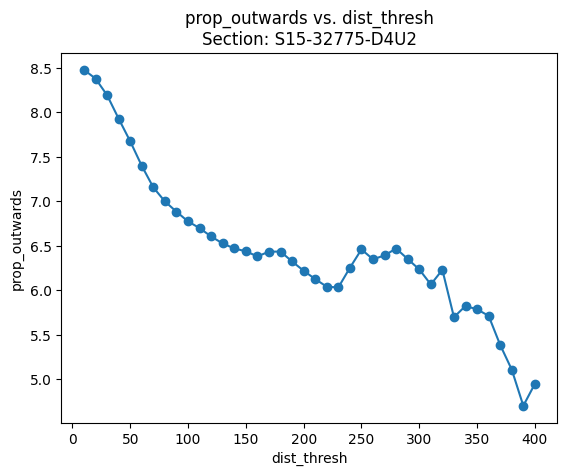

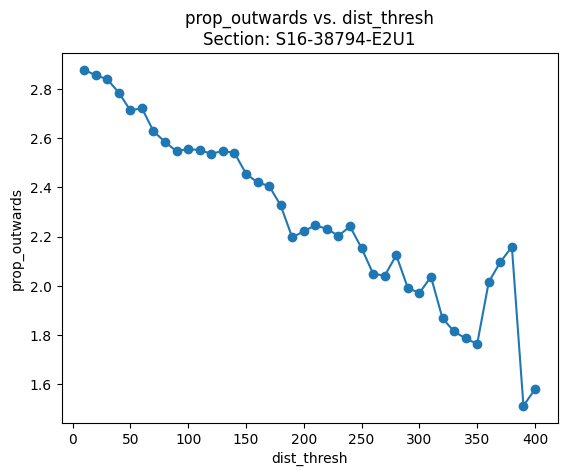

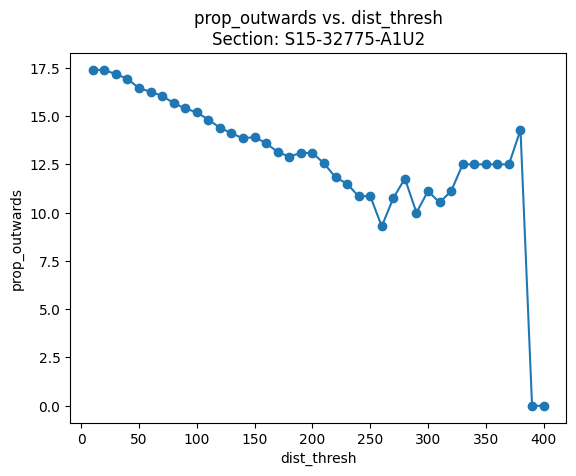

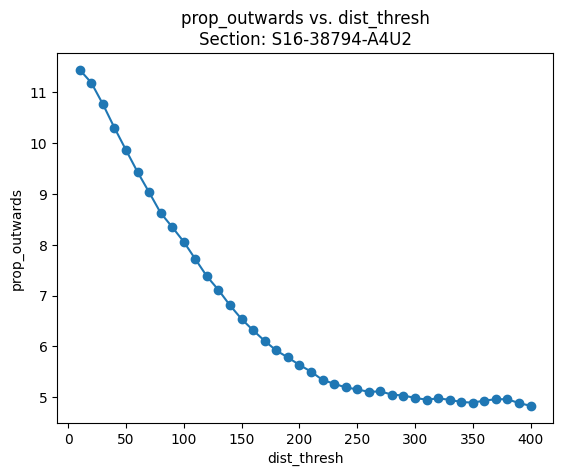

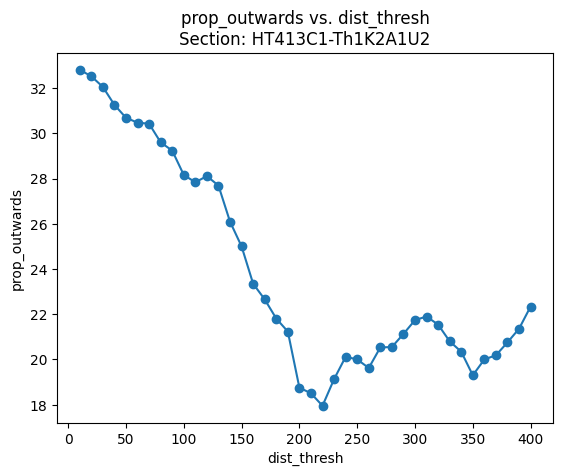

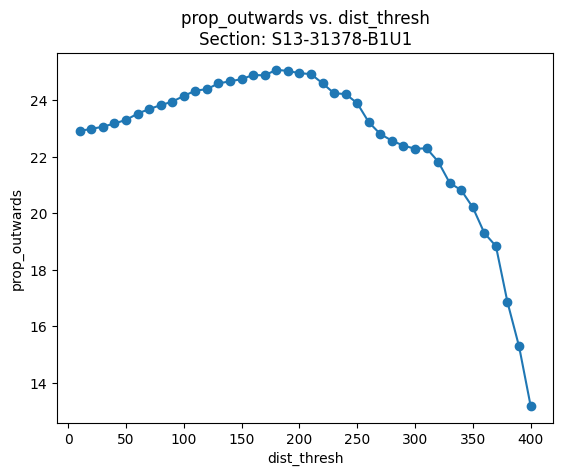

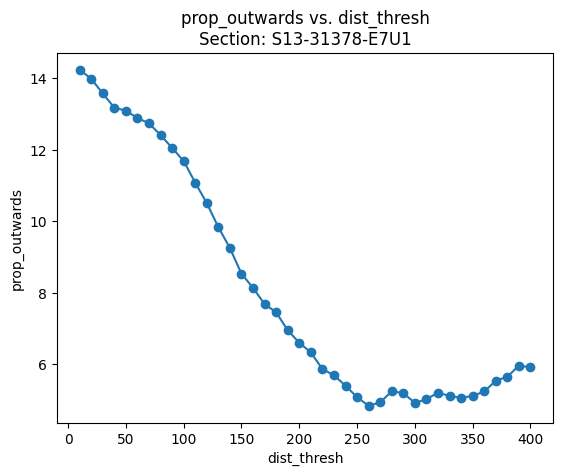

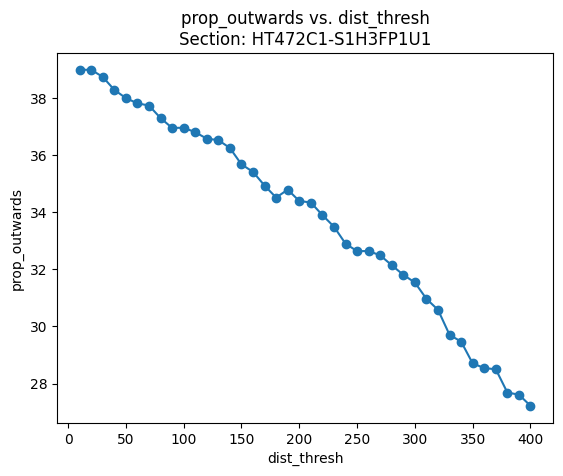

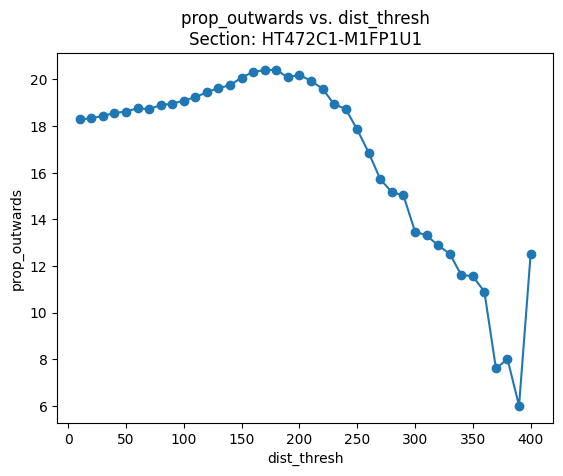

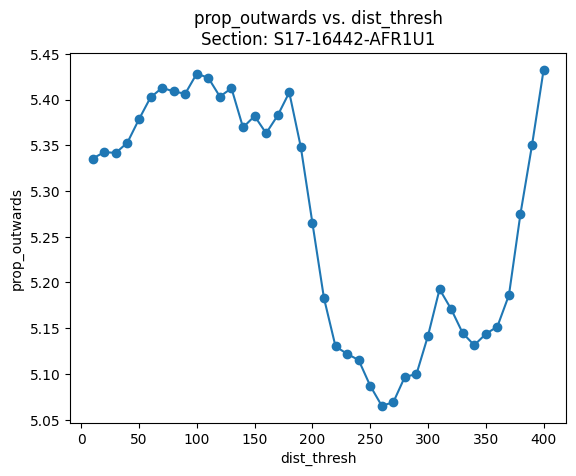

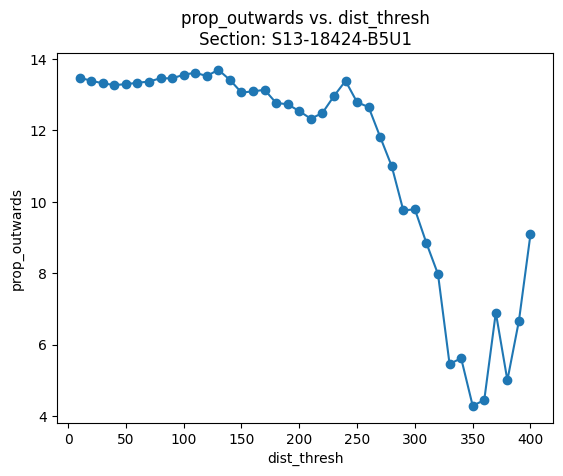

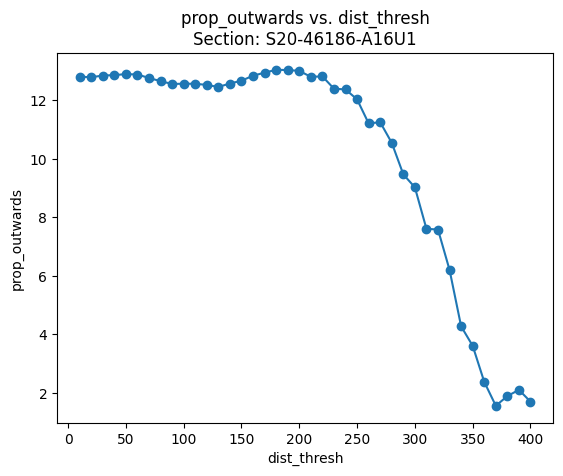

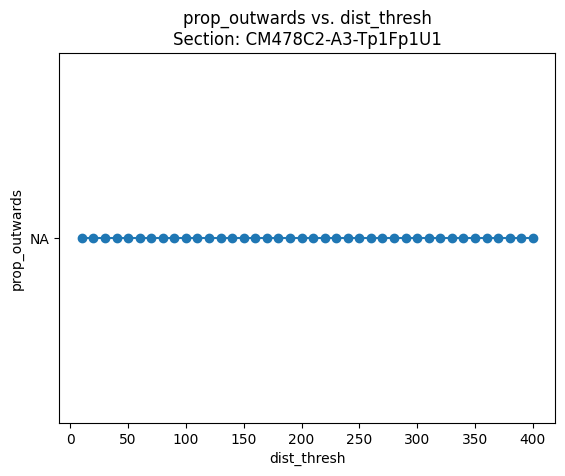

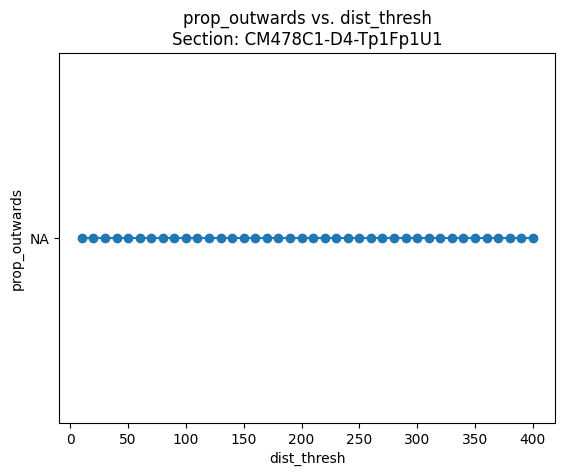

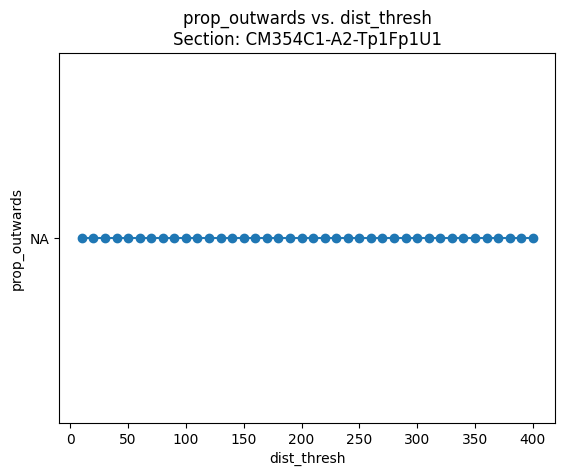

In [83]:
for section_id in section_ids:
    
    # Build a list of dictionaries for the DataFrame
    rows = []
    for dist_thresh in sect_dict[list(sect_dict.keys())[0]].keys():
        prop_inwards, prop_outwards, num_inwards, num_outwards, tot_in, tot_out = sect_dict[section_id][dist_thresh]
        
        row_dict = {
            "dist_thresh": dist_thresh,
            "prop_outwards": prop_outwards
        }
        rows.append(row_dict)
    
    # Create a DataFrame
    df = pd.DataFrame(rows)

    # Sort by dist_thresh if needed
    df.sort_values("dist_thresh", inplace=True)

    # Plot each section_id in a separate figure
    plt.plot(df["dist_thresh"], df["prop_outwards"], linestyle='-', marker='o')
    
    # Add labels and title
    plt.xlabel('dist_thresh')
    plt.ylabel('prop_outwards')
    plt.title(f'prop_outwards vs. dist_thresh\nSection: {section_id}')
    
    # Show the plot (one figure per loop iteration)
    plt.show()
